<a href="https://colab.research.google.com/github/rlaqhtjd-2026/group-8-surveying2/blob/main/02_%EA%B0%9C%EC%9D%B8%EB%B6%84%EC%84%9D/%EC%84%B8%EB%B6%80%EB%AA%A9%EC%A0%81(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

설치 및 초기화

In [1]:
# 필요한 패키지 설치
import sys
import subprocess


subprocess.check_call([
    sys.executable, "-m", "pip", "-q", "install",
    "earthengine-api", "geemap", "pandas",
    "openpyxl", "ipywidgets", "koreanize-matplotlib"
])


import ee
import geemap
import pandas as pd
import numpy as np
import ipywidgets as widgets
import ipyleaflet
import traceback
import io
import requests
import math

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image

from pathlib import Path
from google.colab import files, output
from IPython.display import display, clear_output

import koreanize_matplotlib


# Colab에서 지도 위젯이 정상적으로 보이도록 설정
output.enable_custom_widget_manager()


# Google Earth Engine 프로젝트
PROJECT = "class-2026-508800"


# Sentinel-2 Level-2A 자료
COLLECTION_ID = "COPERNICUS/S2_SR_HARMONIZED"


# 분석 기간
START_DATE = "2026-05-01"
END_DATE = "2026-10-01"


# 전체 영상에 적용할 구름 비율 조건
MAX_CLOUD_PERCENT = 20.0


# NDCI-클로로필-a 회귀식
SLOPE = 191.688874
INTERCEPT = 23.757085


# 과거 채수지점 좌표
# 기준값은 이 좌표가 속한 B5 20m 픽셀 1개에서 추출
SITE_LON = 128.9334638888889
SITE_LAT = 35.34826944444445


# 분석 범위의 중심
# 현재 채수지점 분석 때와 동일한 ROI를 유지하기 위해 고정
ROI_CENTER_LON = 128.9523888889
ROI_CENTER_LAT = 35.33525


# 수체 판별 기준
MNDWI_THRESHOLD = 0.18
NDWI_THRESHOLD = 0.08
MAX_NIR = 0.15


# 결과 저장 폴더
# 기존 현재 채수지점 분석 결과와 분리
OUTPUT_DIR = Path("output") / "과거채수지점"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Google Earth Engine 초기화
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)


# 기준값을 추출할 과거 채수지점
site_point = ee.Geometry.Point([
    SITE_LON,
    SITE_LAT
])


# 기존 분석과 동일한 약 20km × 20km 분석 범위
lat_offset = 10.0 / 111.0
lon_offset = 10.0 / 90.7

roi = ee.Geometry.Rectangle([
    ROI_CENTER_LON - lon_offset,
    ROI_CENTER_LAT - lat_offset,
    ROI_CENTER_LON + lon_offset,
    ROI_CENTER_LAT + lat_offset
])


# 이전 계산 결과 초기화
# 현재 채수지점 기준 결과가 재사용되지 않도록 초기화
analysis_cache = {}
saved_map_state = {}


print("초기화 완료")
print("분석 기준: 과거 채수지점")
print(f"경도: {SITE_LON}")
print(f"위도: {SITE_LAT}")
print("기준: 과거 채수지점 좌표가 속한 20m 픽셀 1개")
print("버퍼 평균은 사용하지 않습니다.")
print("분석 범위: 기존 현재 채수지점 분석과 동일")
print(f"회귀식: Chl-a = {SLOPE} × NDCI + {INTERCEPT}")
print("농도·편차 단위: mg/m³")
print(f"결과 저장 폴더: {OUTPUT_DIR}")

초기화 완료
분석 기준: 과거 채수지점
경도: 128.9334638888889
위도: 35.34826944444445
기준: 과거 채수지점 좌표가 속한 20m 픽셀 1개
버퍼 평균은 사용하지 않습니다.
분석 범위: 기존 현재 채수지점 분석과 동일
회귀식: Chl-a = 191.688874 × NDCI + 23.757085
농도·편차 단위: mg/m³
결과 저장 폴더: output/과거채수지점


전체 영상 조회

In [2]:
# Sentinel-2 영상 조회
s2 = (
    ee.ImageCollection(COLLECTION_ID)
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE",
            MAX_CLOUD_PERCENT
        )
    )
    .sort("system:time_start")
)

# 조회된 영상 수 확인
image_count = int(s2.size().getInfo())

if image_count == 0:
    raise ValueError("조건에 해당하는 영상이 없습니다.")

# 영상 정보 가져오기
metadata = ee.List(
    s2.toList(image_count).map(
        lambda obj: ee.Dictionary({
            "Image_ID": ee.Image(obj).id(),
            "Image_Index": ee.Image(obj).get("system:index"),
            "Date_Time_KST": ee.Image(obj).date().format(
                "YYYY-MM-dd HH:mm",
                "Asia/Seoul"
            ),
            "Cloud_Percent_Global": ee.Image(obj).get(
                "CLOUDY_PIXEL_PERCENTAGE"
            ),
            "MGRS_Tile": ee.Image(obj).get("MGRS_TILE"),
            "Satellite": ee.Image(obj).get("SPACECRAFT_NAME")
        })
    )
).getInfo()

# 전체 영상 목록
candidate_image_table = (
    pd.DataFrame(metadata)
    .sort_values(["Date_Time_KST", "Image_Index"])
    .reset_index(drop=True)
)

candidate_image_table.insert(
    0, "No", range(1, len(candidate_image_table) + 1)
)

candidate_image_table["Date_KST"] = (
    candidate_image_table["Date_Time_KST"].str[:10]
)

candidate_image_table["Analysis_Status"] = "미처리"

# 영상 ID가 짧은 형태로 저장된 경우를 대비해
# 전체 경로로 통일
candidate_image_table["Image_ID"] = (
    candidate_image_table["Image_ID"]
    .astype(str)
    .apply(
        lambda value: value
        if value.startswith(COLLECTION_ID)
        else f"{COLLECTION_ID}/{value}"
    )
)

print(f"조회 영상: {len(candidate_image_table)}장")
print(
    f"서로 다른 촬영 날짜: "
    f"{candidate_image_table['Date_KST'].nunique()}일"
)
print("동일 날짜의 서로 다른 타일은 별도 영상입니다.")

print("\n첫 영상의 전체 ID 확인")
print(candidate_image_table.loc[0, "Image_ID"])

display(candidate_image_table[[
    "No",
    "Date_Time_KST",
    "Satellite",
    "MGRS_Tile",
    "Cloud_Percent_Global",
    "Image_Index"
]])

조회 영상: 19장
서로 다른 촬영 날짜: 13일
동일 날짜의 서로 다른 타일은 별도 영상입니다.

첫 영상의 전체 ID 확인
COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE


,No,Date_Time_KST,Satellite,MGRS_Tile,Cloud_Percent_Global,Image_Index
0,1,2026-05-08 11:17,Sentinel-2B,52SDE,5.836149,20260508T020649_20260508T021227_T52SDE
1,2,2026-05-08 11:17,Sentinel-2B,52SEE,5.079857,20260508T020649_20260508T021227_T52SEE
2,3,2026-05-13 11:17,Sentinel-2C,52SDE,1.342889,20260513T020651_20260513T021205_T52SDE
3,4,2026-05-15 11:17,Sentinel-2A,52SDE,0.266087,20260515T021121_20260515T021122_T52SDE
4,5,2026-05-18 11:17,Sentinel-2B,52SDE,6.823023,20260518T020649_20260518T021212_T52SDE
5,6,2026-05-18 11:17,Sentinel-2B,52SEE,9.440792,20260518T020649_20260518T021212_T52SEE
6,7,2026-06-12 11:17,Sentinel-2C,52SDE,0.148321,20260612T020651_20260612T021313_T52SDE
7,8,2026-06-12 11:17,Sentinel-2C,52SEE,0.035192,20260612T020651_20260612T021313_T52SEE
8,9,2026-07-22 11:17,Sentinel-2C,52SEE,8.951852,20260722T020651_20260722T021351_T52SEE
9,10,2026-08-01 11:17,Sentinel-2C,52SDE,17.945518,20260801T020651_20260801T021347_T52SDE


단일 픽셀 분석 함수

In [3]:
def process_scene(image_id):
    # image_id가 영상 이름만 들어와도
    # 전체 자료 경로를 자동으로 생성
    image_id = str(image_id)

    if not image_id.startswith(COLLECTION_ID):
        image_id = f"{COLLECTION_ID}/{image_id}"

    image = ee.Image(image_id)
    scl = image.select("SCL")

    # 선택 영상의 B5 원래 20m 격자
    grid = image.select("B5").projection()

    # 예비 품질 마스크
    # 4: 식생, 5: 비식생, 6: 수면, 7: 미분류
    clear_mask = (
        scl.eq(4)
        .Or(scl.eq(5))
        .Or(scl.eq(6))
        .Or(scl.eq(7))
    )

    # 정수 저장값을 반사도로 변환
    reflectance = (
        image.select(["B3", "B4", "B5", "B8", "B11"])
        .multiply(0.0001)
        .updateMask(clear_mask)
    )

    # 10m 밴드를 B5의 20m 격자에 맞추기
    def aggregate_20m(band):
        return (
            reflectance.select(band)
            .reduceResolution(
                reducer=ee.Reducer.mean(),
                maxPixels=64
            )
            .reproject(crs=grid)
        )

    green = aggregate_20m("B3")
    red = aggregate_20m("B4")
    nir = aggregate_20m("B8")

    red_edge = (
        reflectance.select("B5")
        .reproject(crs=grid)
    )

    swir1 = (
        reflectance.select("B11")
        .reproject(crs=grid)
    )

    # 수체 판별 지수
    mndwi_den = green.add(swir1)
    ndwi_den = green.add(nir)

    mndwi = (
        green.subtract(swir1)
        .divide(mndwi_den)
        .updateMask(mndwi_den.gt(0))
    )

    ndwi = (
        green.subtract(nir)
        .divide(ndwi_den)
        .updateMask(ndwi_den.gt(0))
    )

    # 수면 분류 또는 수체 지수 조건을 만족하는 픽셀 유지
    water_mask = (
        scl.eq(6)
        .Or(
            mndwi.gt(MNDWI_THRESHOLD)
            .And(ndwi.gt(NDWI_THRESHOLD))
            .And(nir.lt(MAX_NIR))
        )
        .And(clear_mask)
    )

    # NDCI 계산
    denominator = red_edge.add(red)

    ndci = (
        red_edge.subtract(red)
        .divide(denominator)
        .updateMask(
            denominator.gt(0)
            .And(red.gte(0))
            .And(red_edge.gte(0))
        )
        .updateMask(water_mask)
        .rename("NDCI")
        .clip(roi)
    )

    # 회귀식을 이용한 추정 클로로필-a
    chla = (
        ndci.multiply(SLOPE)
        .add(INTERCEPT)
        .rename("Chla_est_mg_m3")
    )

    # 과거 채수지점 좌표가 속한 픽셀 1개 추출
    # 초기화 단계에서 정의한 site_point를 사용
    # 버퍼 평균은 사용하지 않음
    site_stats = ndci.addBands(chla).reduceRegion(
        reducer=ee.Reducer.first(),
        geometry=site_point,
        scale=20,
        maxPixels=1000
    ).getInfo()

    site_ndci = site_stats.get("NDCI")
    site_chla = site_stats.get("Chla_est_mg_m3")

    # 기준 픽셀의 값이 있는지 확인
    site_valid = (
        site_ndci is not None
        and site_chla is not None
    )

    if site_valid:
        site_ndci = float(site_ndci)
        site_chla = float(site_chla)

        # 편차 = 해당 픽셀 추정 농도
        #        - 과거 채수지점 픽셀 추정 농도
        deviation = (
            chla.subtract(site_chla)
            .rename("Deviation_mg_m3")
        )

    else:
        # 기준 픽셀이 결측이면 편차도 결측 처리
        # 주변 픽셀 값으로 대체하지 않음
        deviation = (
            chla.multiply(0)
            .updateMask(ee.Image.constant(0))
            .rename("Deviation_mg_m3")
        )

    # 기존 지도 표시용 사각형 유지
    # 실제 B5 픽셀 경계가 아니라 지점 주변의 약 20m 표시 영역
    # 이 도형은 값 추출에 사용하지 않음
    site_pixel_buffer = site_point.buffer(10)
    pixel_geometry = site_pixel_buffer.bounds()

    stack = (
        ndci
        .addBands(chla)
        .addBands(deviation)
    )

    return {
        "raw": image,
        "grid": grid,
        "ndci": ndci,
        "chla": chla,
        "deviation": deviation,
        "stack": stack,
        "site_ndci": site_ndci,
        "site_chla": site_chla,
        "site_valid": site_valid,
        "site_pixel_geometry": pixel_geometry
    }


def get_result(index):
    image_id = candidate_image_table.loc[
        index, "Image_ID"
    ]

    # 이미 계산한 영상은 저장된 결과 사용
    if image_id not in analysis_cache:
        result = process_scene(image_id)
        analysis_cache[image_id] = result

    return analysis_cache[image_id]


print("단일 픽셀 분석 함수 준비 완료")
print("기준: 과거 채수지점 좌표가 속한 20m 픽셀 1개")
print(f"기준 좌표: 경도 {SITE_LON}, 위도 {SITE_LAT}")
print("채수지점 주변의 버퍼 평균은 사용하지 않습니다.")
print("기준 픽셀이 결측이면 주변 픽셀로 대체하지 않습니다.")
print("채수지점 픽셀 값 추출 방식: scale=20")

단일 픽셀 분석 함수 준비 완료
기준: 과거 채수지점 좌표가 속한 20m 픽셀 1개
기준 좌표: 경도 128.9334638888889, 위도 35.34826944444445
채수지점 주변의 버퍼 평균은 사용하지 않습니다.
기준 픽셀이 결측이면 주변 픽셀로 대체하지 않습니다.
채수지점 픽셀 값 추출 방식: scale=20


**기준 픽셀 값이 있는 영상만 선정**

이 단계에서 각 영상의 기준 픽셀을 실제로 검사합니다. 값이 있는 영상만 이후 지도와 엑셀에 사용합니다.

In [4]:
# 이전 계산 결과 초기화
analysis_cache = {}


# 영상 선정 결과 저장
selection_records = []
accepted_indices = []


print("과거 채수지점의 단일 픽셀 값 확인을 시작합니다.")
print(f"기준 좌표: 경도 {SITE_LON}, 위도 {SITE_LAT}")
print("구름·수면 마스크를 적용한 뒤 값이 있는 영상만 선정합니다.")
print("영상 수에 따라 시간이 걸릴 수 있습니다.\n")


total = len(candidate_image_table)


for position, (index, row) in enumerate(
    candidate_image_table.iterrows(),
    start=1
):
    record = {
        "Image_ID": row["Image_ID"],
        "Image_Index": row["Image_Index"],
        "Date_Time_KST": row["Date_Time_KST"],
        "선정_여부": False,
        "검사_결과": "",
        "기준_픽셀_NDCI": None,
        "기준_픽셀_추정농도_mg_m3": None,
        "오류_내용": ""
    }

    print(
        f"[{position}/{total}] "
        f"{row['Date_Time_KST']} | {row['Image_Index']}",
        end=" → "
    )

    try:
        image_id = row["Image_ID"]

        if image_id not in analysis_cache:
            analysis_cache[image_id] = process_scene(
                image_id
            )

        result = analysis_cache[image_id]

        valid = (
            result["site_valid"]
            and result["site_ndci"] is not None
            and result["site_chla"] is not None
            and math.isfinite(
                float(result["site_ndci"])
            )
            and math.isfinite(
                float(result["site_chla"])
            )
        )

        if valid:
            accepted_indices.append(index)

            record["선정_여부"] = True
            record["검사_결과"] = "선정"

            record["기준_픽셀_NDCI"] = float(
                result["site_ndci"]
            )

            record["기준_픽셀_추정농도_mg_m3"] = float(
                result["site_chla"]
            )

            print(
                "선정 "
                f"(추정 농도 {result['site_chla']:.2f} mg/m³)"
            )

        else:
            record["검사_결과"] = (
                "제외: 기준 픽셀 결측"
            )

            print("제외: 기준 픽셀 결측")

    except Exception as error:
        record["검사_결과"] = (
            "판정 보류: 처리 오류"
        )

        record["오류_내용"] = str(error)

        print("판정 보류: 처리 오류")

    selection_records.append(record)


# 영상 선정 내역
selection_table = pd.DataFrame(
    selection_records
)


# 이후 지도·엑셀에서 사용할 영상은
# 과거 채수지점의 기준 픽셀 값이 있는 영상만 선정
image_table = (
    candidate_image_table.loc[accepted_indices]
    .copy()
    .reset_index(drop=True)
)


if image_table.empty:
    display(selection_table)

    raise ValueError(
        "선정된 영상이 없습니다. "
        "과거 채수지점 기준 픽셀의 결측과 "
        "처리 오류 내역을 확인하세요."
    )


image_table["No"] = range(
    1,
    len(image_table) + 1
)

image_table["Analysis_Status"] = (
    "기준 픽셀 유효"
)

image_table["Site_Pixel_Chla_mg_m3"] = [
    analysis_cache[image_id]["site_chla"]
    for image_id in image_table["Image_ID"]
]


print("\n과거 채수지점 기준 영상 선정 완료")
print(f"검사 대상: {len(candidate_image_table)}장")
print(f"선정 영상: {len(image_table)}장")

print(
    "처리 오류: "
    f"{(selection_table['검사_결과'] == '판정 보류: 처리 오류').sum()}장"
)


display(
    image_table[[
        "No",
        "Date_Time_KST",
        "Image_Index",
        "Site_Pixel_Chla_mg_m3"
    ]]
)

display(selection_table)

과거 채수지점의 단일 픽셀 값 확인을 시작합니다.
기준 좌표: 경도 128.9334638888889, 위도 35.34826944444445
구름·수면 마스크를 적용한 뒤 값이 있는 영상만 선정합니다.
영상 수에 따라 시간이 걸릴 수 있습니다.

[1/19] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE → 선정 (추정 농도 17.75 mg/m³)
[2/19] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SEE → 제외: 기준 픽셀 결측
[3/19] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE → 선정 (추정 농도 20.22 mg/m³)
[4/19] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE → 선정 (추정 농도 24.54 mg/m³)
[5/19] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE → 선정 (추정 농도 31.50 mg/m³)
[6/19] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SEE → 제외: 기준 픽셀 결측
[7/19] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE → 선정 (추정 농도 42.77 mg/m³)
[8/19] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SEE → 제외: 기준 픽셀 결측
[9/19] 2026-07-22 11:17 | 20260722T020651_20260722T021351_T52SEE → 제외: 기준 픽셀 결측
[10/19] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE → 선정 (추정 농도 41.16 mg/m³)
[1

,No,Date_Time_KST,Image_Index,Site_Pixel_Chla_mg_m3
0,1,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,17.754302
1,2,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,20.222397
2,3,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,24.539915
3,4,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,31.501018
4,5,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,42.771623
5,6,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,41.164783
6,7,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,44.374476
7,8,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,23.197137
8,9,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,49.608256


,Image_ID,Image_Index,Date_Time_KST,선정_여부,검사_결과,기준_픽셀_NDCI,기준_픽셀_추정농도_mg_m3,오류_내용
0,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20...,20260508T020649_20260508T021227_T52SDE,2026-05-08 11:17,True,선정,-0.031315,17.754302,
1,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20...,20260508T020649_20260508T021227_T52SEE,2026-05-08 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
2,COPERNICUS/S2_SR_HARMONIZED/20260513T020651_20...,20260513T020651_20260513T021205_T52SDE,2026-05-13 11:17,True,선정,-0.018440,20.222397,
3,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20...,20260515T021121_20260515T021122_T52SDE,2026-05-15 11:17,True,선정,0.004084,24.539915,
4,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20...,20260518T020649_20260518T021212_T52SDE,2026-05-18 11:17,True,선정,0.040398,31.501018,
5,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20...,20260518T020649_20260518T021212_T52SEE,2026-05-18 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
6,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20...,20260612T020651_20260612T021313_T52SDE,2026-06-12 11:17,True,선정,0.099195,42.771623,
7,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20...,20260612T020651_20260612T021313_T52SEE,2026-06-12 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
8,COPERNICUS/S2_SR_HARMONIZED/20260722T020651_20...,20260722T020651_20260722T021351_T52SEE,2026-07-22 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
9,COPERNICUS/S2_SR_HARMONIZED/20260801T020651_20...,20260801T020651_20260801T021347_T52SDE,2026-08-01 11:17,True,선정,0.090812,41.164783,


지도 범례 설정

In [5]:
# =========================================================
# 1. 분석 기준 표시
# =========================================================

SITE_LABEL = "과거 채수지점"

# 실제 분석 기준 좌표는 초기화 단계에서 설정
# SITE_LON = 128.9334638888889
# SITE_LAT = 35.34826944444445
#
# site_point = ee.Geometry.Point([
#     SITE_LON,
#     SITE_LAT
# ])
#
# 기준 변경 시 초기화 단계에서 analysis_cache도 초기화한 뒤
# 영상 선정 및 분석 단계를 다시 실행해야 함


# =========================================================
# 2. 음수 추정 농도의 지도 표시 설정
# =========================================================

# 해당 픽셀의 추정 Chl-a가 음수일 때 적용
# 원래 분석값은 변경하지 않고 지도에서만 회색 표시
NEGATIVE_CHLA_COLOR = "808080"
NEGATIVE_CHLA_LABEL = "결측(음수 추정값)"


# =========================================================
# 3. NDCI 지도 색상
# 현재 지점 분석과 동일하게 유지
# =========================================================

NDCI_STYLE = {
    "min": -0.3,
    "max": 0.5,
    "palette": [
        "2166ac",
        "67a9cf",
        "ffffbf",
        "a6d96a",
        "1a9850"
    ]
}


# =========================================================
# 4. 추정 클로로필-a 지도 색상
# 현재 지점 분석과 동일하게 유지
# =========================================================

CHLA_STYLE = {
    "min": 0,
    "max": 100,
    "palette": [
        "313695",
        "74add1",
        "abd9e9",
        "ffffbf",
        "fdae61",
        "d73027"
    ]
}


# =========================================================
# 5. 편차 지도 색상: 8개 구간
# =========================================================

# D = 해당 픽셀 추정 Chl-a
#     - 과거 채수지점 기준 픽셀 추정 Chl-a

DEVIATION_COLORS = [
    "053061",
    "2166ac",
    "92c5de",
    "d1e5f0",
    "fddbc7",
    "f4a582",
    "d6604d",
    "67001f"
]


# =========================================================
# 6. 편차 범례
# 회색 결측 표시는 별도 범례에 추가
# =========================================================

DEVIATION_LEGEND = {
    "D < −15": "053061",
    "−15 ≤ D < −10": "2166ac",
    "−10 ≤ D < −5": "92c5de",
    "−5 ≤ D < 0": "d1e5f0",
    "0 ≤ D ≤ 5": "fddbc7",
    "5 < D ≤ 10": "f4a582",
    "10 < D ≤ 15": "d6604d",
    "D > 15": "67001f"
}


# =========================================================
# 7. 편차 분류 함수
# =========================================================

def classify_deviation(deviation):
    # 기본 구간: -5 ≤ D < 0
    # 원래 편차 영상의 마스크 유지
    classes = deviation.multiply(0).add(3)

    return (
        classes
        .where(
            deviation.lt(-15),
            0
        )
        .where(
            deviation.gte(-15)
            .And(deviation.lt(-10)),
            1
        )
        .where(
            deviation.gte(-10)
            .And(deviation.lt(-5)),
            2
        )
        .where(
            deviation.gte(0)
            .And(deviation.lte(5)),
            4
        )
        .where(
            deviation.gt(5)
            .And(deviation.lte(10)),
            5
        )
        .where(
            deviation.gt(10)
            .And(deviation.lte(15)),
            6
        )
        .where(
            deviation.gt(15),
            7
        )
        .toByte()
        .rename("Deviation_Class")
    )


# =========================================================
# 8. 기존 지도·PNG 단계와 연결하기 위한 이름
# =========================================================

DEVIATION_COLORS_8 = DEVIATION_COLORS

DEVIATION_LABELS_8 = list(
    DEVIATION_LEGEND.keys()
)

DEVIATION_LEGEND_8 = dict(
    reversed(
        list(DEVIATION_LEGEND.items())
    )
)

classify_deviation_8 = classify_deviation


# =========================================================
# 9. 회색 표시를 포함한 별도 범례
# 기존 편차 8개 구간 범례와 분리
# =========================================================

DEVIATION_LEGEND_WITH_MISSING = {
    **DEVIATION_LEGEND,
    NEGATIVE_CHLA_LABEL: NEGATIVE_CHLA_COLOR
}


# =========================================================
# 10. 설정 안내
# =========================================================

print("세부목적 3 지도 범례 준비 완료")
print(f"분석 기준 표시: {SITE_LABEL}")
print(
    "편차 = 해당 픽셀 추정 Chl-a"
    " - 과거 채수지점 기준 픽셀 추정 Chl-a"
)
print("편차: 총 8개 구간")
print("중앙 구간: −5 ≤ D < 0 / 0 ≤ D ≤ 5")
print(
    f"별도 표시: {NEGATIVE_CHLA_LABEL} → 회색"
)
print(
    "회색 판정 기준: 편차의 음수가 아니라 "
    "해당 픽셀의 추정 Chl-a < 0"
)
print("색상·편차 구간은 현재 채수지점 분석과 동일합니다.")

세부목적 3 지도 범례 준비 완료
분석 기준 표시: 과거 채수지점
편차 = 해당 픽셀 추정 Chl-a - 과거 채수지점 기준 픽셀 추정 Chl-a
편차: 총 8개 구간
중앙 구간: −5 ≤ D < 0 / 0 ≤ D ≤ 5
별도 표시: 결측(음수 추정값) → 회색
회색 판정 기준: 편차의 음수가 아니라 해당 픽셀의 추정 Chl-a < 0
색상·편차 구간은 현재 채수지점 분석과 동일합니다.


**지도 표시**

영상을 선택하거나 지도 종류를 바꾸면 자동으로 갱신됩니다. 기준 픽셀은 노란 경계, 현재 채수지점은 마커로 표시됩니다.

In [6]:
import ee
import geemap
import ipyleaflet
import ipywidgets as widgets
import numpy as np
import traceback

from IPython.display import display, clear_output


# =========================================================
# 1. 표시 설정 및 분석 기준 확인
# =========================================================

SITE_LABEL = "과거 채수지점"

NEGATIVE_CHLA_COLOR = "808080"
NEGATIVE_CHLA_LABEL = "결측(음수 추정값)"

PAST_SITE_LON = 128.9334638888889
PAST_SITE_LAT = 35.34826944444445

if not (
    np.isclose(
        SITE_LON,
        PAST_SITE_LON,
        rtol=0,
        atol=1e-8
    )
    and np.isclose(
        SITE_LAT,
        PAST_SITE_LAT,
        rtol=0,
        atol=1e-8
    )
):
    raise ValueError(
        "SITE_LON·SITE_LAT가 과거 채수지점 좌표가 아닙니다. "
        "과거 지점 좌표로 초기화한 뒤 "
        "영상 선정 단계부터 다시 실행해 주세요."
    )

# site_point도 과거 지점으로 설정되어 있는지 확인
site_coordinates = site_point.coordinates().getInfo()

if not (
    np.isclose(
        site_coordinates[0],
        PAST_SITE_LON,
        rtol=0,
        atol=1e-8
    )
    and np.isclose(
        site_coordinates[1],
        PAST_SITE_LAT,
        rtol=0,
        atol=1e-8
    )
):
    raise ValueError(
        "site_point가 과거 채수지점 좌표가 아닙니다. "
        "초기화·분석 단계를 다시 실행해 주세요."
    )

if image_table.empty:
    raise ValueError(
        "선정된 영상이 없습니다. "
        "과거 지점 기준 영상 선정 단계를 확인해 주세요."
    )

if len(DEVIATION_COLORS) != 8:
    raise ValueError(
        "편차 색상은 8개여야 합니다."
    )

if len(DEVIATION_LEGEND) != 8:
    raise ValueError(
        "기본 편차 범례는 8개여야 합니다. "
        "회색 결측 표시는 별도로 추가합니다."
    )

if "analysis_cache" not in globals():
    analysis_cache = {}

if "saved_map_state" not in globals():
    saved_map_state = {}


# =========================================================
# 2. 선정된 영상 선택 목록
# =========================================================

image_options = [
    (
        f"{int(row.No):02d} | {row.Date_Time_KST} KST"
        f" | {row.MGRS_Tile}"
        f" | 구름 {row.Cloud_Percent_Global:.1f}%"
        f" | 기준 농도 {row.Site_Pixel_Chla_mg_m3:.2f} mg/m³",
        index
    )
    for index, row in image_table.iterrows()
]

image_selector = widgets.Dropdown(
    options=image_options,
    description="위성영상:",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "initial"}
)

mode_selector = widgets.ToggleButtons(
    options=[
        ("NDCI", "ndci"),
        ("추정 클로로필-a", "chla"),
        ("과거 채수지점 대비 편차", "deviation")
    ],
    value="deviation",
    description="지도:"
)

map_button = widgets.Button(
    description="지도 다시 표시",
    button_style="success"
)

main_output = widgets.Output()


# =========================================================
# 3. 영상 ID 기준 분석 결과 조회
# =========================================================

def get_result_by_image_id(image_id):
    image_id = str(image_id)

    if not image_id.startswith(COLLECTION_ID):
        image_id = f"{COLLECTION_ID}/{image_id}"

    if image_id not in analysis_cache:
        analysis_cache[image_id] = process_scene(
            image_id
        )

    return analysis_cache[image_id]


# =========================================================
# 4. 지도 표시
# =========================================================

def draw_map(_=None):
    map_button.disabled = True
    image_selector.disabled = True
    mode_selector.disabled = True

    # 지도 표시 실패 시 이전 지도가 저장되지 않도록 초기화
    saved_map_state.clear()

    with main_output:
        clear_output(wait=True)
        print("선택 영상 분석 중")

    try:
        index = image_selector.value
        mode = mode_selector.value
        row = image_table.loc[index].copy()

        result = get_result_by_image_id(
            row["Image_ID"]
        )

        if not result["site_valid"]:
            with main_output:
                clear_output(wait=True)

                print(
                    "과거 채수지점 기준 픽셀 결측: "
                    "지도 표시 불가"
                )
                print(f"영상: {row.Image_Index}")
                print(
                    "주변 픽셀로 기준값을 대체하지 않습니다."
                )

            return

        # -------------------------------------------------
        # 표시용 마스크
        # 원래 result의 농도·편차 값은 변경하지 않음
        # -------------------------------------------------

        chla_image = ee.Image(
            result["chla"]
        )

        # 추정 농도가 0 이상인 픽셀
        nonnegative_mask = chla_image.gte(0)

        # 추정 농도가 음수인 픽셀만 남김
        negative_chla_layer = (
            chla_image.lt(0)
            .selfMask()
            .rename("Negative_Chla")
        )

        ndci_display = (
            ee.Image(result["ndci"])
            .updateMask(nonnegative_mask)
        )

        chla_display = (
            chla_image
            .updateMask(nonnegative_mask)
        )

        deviation_display = (
            classify_deviation(
                result["deviation"]
            )
            .updateMask(nonnegative_mask)
        )

        with main_output:
            clear_output(wait=True)

            print(
                f"촬영 시각: {row.Date_Time_KST} KST"
            )
            print(f"영상: {row.Image_Index}")
            print(
                f"위성 / 타일: "
                f"{row.Satellite} / {row.MGRS_Tile}"
            )

            print(
                "기준: 과거 채수지점 좌표가 속한 "
                "20m 픽셀 1개"
            )
            print(
                f"기준 좌표: 경도 {SITE_LON:.8f}, "
                f"위도 {SITE_LAT:.8f}"
            )
            print(
                f"기준 픽셀 NDCI: "
                f"{result['site_ndci']:.4f}"
            )
            print(
                f"기준 픽셀 추정 Chl-a: "
                f"{result['site_chla']:.2f} mg/m³"
            )

            if result["site_chla"] < 0:
                print(
                    "주의: 과거 지점 기준 픽셀의 "
                    "추정 농도가 음수입니다."
                )
                print(
                    "기준값을 대체하지 않으며, "
                    "편차는 기존 음수 기준값으로 계산된 값입니다."
                )

            print(
                "회색: 추정 Chl-a가 음수인 픽셀"
                " — 지도에서 결측으로 표시"
            )

            # -------------------------------------------------
            # 지도 생성
            # -------------------------------------------------

            m = geemap.Map(
                center=[SITE_LAT, SITE_LON],
                zoom=14,
                height="650px"
            )

            m.add_basemap(
                "Esri.WorldImagery"
            )

            rgb = (
                result["raw"]
                .select(["B4", "B3", "B2"])
                .multiply(0.0001)
                .clip(roi)
            )

            m.addLayer(
                rgb,
                {"min": 0, "max": 0.2},
                "선택 촬영일 Sentinel-2 RGB",
                False
            )

            # -------------------------------------------------
            # NDCI 지도
            # -------------------------------------------------

            if mode == "ndci":
                m.addLayer(
                    ndci_display,
                    NDCI_STYLE,
                    "NDCI [무차원]",
                    True,
                    0.85
                )

                m.add_colorbar(
                    vis_params=NDCI_STYLE,
                    label="NDCI [무차원]",
                    position="bottomright"
                )

            # -------------------------------------------------
            # 추정 Chl-a 지도
            # -------------------------------------------------

            elif mode == "chla":
                m.addLayer(
                    chla_display,
                    CHLA_STYLE,
                    "추정 클로로필-a [mg/m³]",
                    True,
                    0.85
                )

                m.add_colorbar(
                    vis_params=CHLA_STYLE,
                    label="추정 Chl-a [mg/m³]",
                    position="bottomright"
                )

            # -------------------------------------------------
            # 과거 채수지점 대비 편차 지도
            # -------------------------------------------------

            else:
                m.addLayer(
                    deviation_display,
                    {
                        "min": 0,
                        "max": 7,
                        "palette": DEVIATION_COLORS
                    },
                    "과거 채수지점 픽셀 대비 편차 [mg/m³]",
                    True,
                    0.85
                )

                print(
                    "D = 해당 픽셀 추정 농도"
                    " − 과거 채수지점 픽셀 추정 농도"
                )
                print(
                    "빨강: 주변이 더 높음"
                    " / 파랑: 주변이 더 낮음"
                )
                print(
                    "편차 구간: 5 mg/m³ 단위"
                )

            # -------------------------------------------------
            # 음수 추정 농도 회색 레이어
            # 모든 지도 모드에 공통 적용
            # -------------------------------------------------

            m.addLayer(
                negative_chla_layer,
                {
                    "min": 0,
                    "max": 1,
                    "palette": [
                        NEGATIVE_CHLA_COLOR,
                        NEGATIVE_CHLA_COLOR
                    ]
                },
                NEGATIVE_CHLA_LABEL,
                True,
                1.0
            )

            # -------------------------------------------------
            # 범례
            # -------------------------------------------------

            if mode == "deviation":
                display_legend = dict(
                    DEVIATION_LEGEND
                )

                display_legend[
                    NEGATIVE_CHLA_LABEL
                ] = NEGATIVE_CHLA_COLOR

                m.add_legend(
                    title="편차 D [mg/m³]",
                    legend_dict=display_legend,
                    position="bottomright",
                    style={
                        "position": "absolute",
                        "z_index": 9999999,
                        "border": "1px solid gray",
                        "background":
                            "rgba(255, 255, 255, 0.90)",
                        "padding": "7px",
                        "fontSize": "10px",
                        "lineHeight": "15px",
                        "width": "190px",
                        "maxHeight": "230px",
                        "overflow": "auto"
                    }
                )

            else:
                m.add_legend(
                    title="결측 표시",
                    legend_dict={
                        NEGATIVE_CHLA_LABEL:
                            NEGATIVE_CHLA_COLOR
                    },
                    position="bottomleft"
                )

            # -------------------------------------------------
            # 기준 지점 표시 영역
            # 기존 도형을 그대로 사용
            # -------------------------------------------------

            pixel_outline = ee.FeatureCollection([
                ee.Feature(
                    result["site_pixel_geometry"]
                )
            ]).style(
                color="FFFF00",
                fillColor="00000000",
                width=3
            )

            m.addLayer(
                pixel_outline,
                {},
                "과거 기준 지점 표시 영역",
                True
            )

            # -------------------------------------------------
            # 과거 채수지점 마커
            # -------------------------------------------------

            marker = ipyleaflet.Marker(
                location=(SITE_LAT, SITE_LON),
                title=SITE_LABEL,
                draggable=False
            )

            popup_text = (
                f"<b>{SITE_LABEL}</b><br>"
                f"경도: {SITE_LON:.8f}<br>"
                f"위도: {SITE_LAT:.8f}<br>"
                "추출 방식: 좌표가 속한 픽셀 1개<br>"
                f"NDCI: {result['site_ndci']:.4f}<br>"
                "추정 Chl-a: "
                f"{result['site_chla']:.2f} mg/m³"
            )

            marker.popup = widgets.HTML(
                value=popup_text
            )

            m.add_layer(marker)

            # -------------------------------------------------
            # 기존 연구지역 ROI 유지
            # -------------------------------------------------

            boundary = ee.FeatureCollection([
                ee.Feature(roi)
            ]).style(
                color="FF0000",
                fillColor="00000000",
                width=2
            )

            m.addLayer(
                boundary,
                {},
                "연구지역 ROI",
                True
            )

            # -------------------------------------------------
            # 실제 표시한 지도 상태 보관
            # -------------------------------------------------

            saved_map_state.update({
                "map": m,
                "result": result,
                "row": row.copy(),
                "mode": mode,
                "site_label": SITE_LABEL,
                "site_lon": SITE_LON,
                "site_lat": SITE_LAT
            })

            display(m)

    except Exception as error:
        with main_output:
            clear_output(wait=True)

            print(
                "지도 표시 실패:",
                error
            )

            traceback.print_exc()

    finally:
        map_button.disabled = False
        image_selector.disabled = False
        mode_selector.disabled = False


# =========================================================
# 5. 이벤트 연결
# =========================================================

def on_selection_change(change):
    if change["name"] == "value":
        draw_map()


image_selector.observe(
    on_selection_change,
    names="value"
)

mode_selector.observe(
    on_selection_change,
    names="value"
)

map_button.on_click(
    draw_map
)


# =========================================================
# 6. 화면 표시
# =========================================================

display(
    widgets.VBox([
        widgets.HTML(
            "<p><b>과거 채수지점 기준 분석 지도</b><br>"
            "영상을 선택하거나 지도 종류를 변경하면 "
            "자동으로 갱신됩니다.<br>"
            "추정 Chl-a가 음수인 픽셀은 "
            "회색의 결측(음수 추정값)으로 표시합니다.</p>"
        ),
        image_selector,
        mode_selector,
        map_button,
        main_output
    ])
)

draw_map()

지도 저장

In [8]:
from matplotlib.patches import Patch, Polygon, Rectangle
from pathlib import Path
from PIL import Image
from google.colab import files
from IPython.display import display, clear_output

import ee
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np

import io
import math
import requests
import traceback
import zipfile


# =========================================================
# 1. 표시 설정
# =========================================================

BACKGROUND_STRENGTH = 0.65
ANALYSIS_OPACITY = 0.90

UNIT_MG_M3 = r"mg/m$^{3}$"

SITE_LABEL = "과거 채수지점"

PAST_SITE_LON = 128.9334638888889
PAST_SITE_LAT = 35.34826944444445

NEGATIVE_CHLA_COLOR = "808080"
NEGATIVE_CHLA_LABEL = "결측(음수 추정값)"

plt.rcParams["axes.unicode_minus"] = False


# =========================================================
# 2. 필수 항목 및 기준 좌표 확인
# =========================================================

required_names = [
    "roi",
    "SITE_LON",
    "SITE_LAT",
    "site_point",
    "COLLECTION_ID",
    "OUTPUT_DIR",
    "image_table",
    "process_scene",
    "classify_deviation",
    "DEVIATION_COLORS",
    "DEVIATION_LEGEND"
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "먼저 과거 지점 초기화·분석 단계를 실행해 주세요. "
        "누락 항목: "
        + ", ".join(missing_names)
    )

if not np.allclose(
    [SITE_LON, SITE_LAT],
    [PAST_SITE_LON, PAST_SITE_LAT],
    rtol=0,
    atol=1e-8
):
    raise ValueError(
        "SITE_LON·SITE_LAT가 과거 채수지점 좌표가 아닙니다. "
        "과거 지점으로 초기화한 뒤 분석 단계를 다시 실행해 주세요."
    )

site_coordinates = site_point.coordinates().getInfo()

if not np.allclose(
    site_coordinates,
    [PAST_SITE_LON, PAST_SITE_LAT],
    rtol=0,
    atol=1e-8
):
    raise ValueError(
        "site_point가 과거 채수지점 좌표가 아닙니다. "
        "초기화 단계부터 다시 실행해 주세요."
    )

if len(DEVIATION_COLORS) != 8:
    raise ValueError(
        "편차 색상은 8개여야 합니다."
    )

if len(DEVIATION_LEGEND) != 8:
    raise ValueError(
        "기본 편차 범례는 8개여야 합니다. "
        "회색 결측 범례는 별도로 추가합니다."
    )

if image_table.empty:
    raise ValueError(
        "선정된 영상이 없습니다."
    )

if "analysis_cache" not in globals():
    analysis_cache = {}


# =========================================================
# 3. 공통 함수
# =========================================================

def safe_name(text):
    return (
        str(text)
        .replace("/", "_")
        .replace(":", "_")
        .replace(" ", "_")
    )


def get_displayed_map():
    state = globals().get("saved_map_state")

    if not state:
        raise ValueError(
            "먼저 과거 채수지점 기준 분석 지도를 표시해 주세요."
        )

    # 직전 과거 지점 지도 코드에서 기록한 좌표 확인
    if (
        state.get("site_lon") is None
        or state.get("site_lat") is None
    ):
        raise ValueError(
            "지도 상태에 기준 좌표 정보가 없습니다. "
            "수정한 과거 지점 지도 표시 셀을 다시 실행해 주세요."
        )

    if not np.allclose(
        [state["site_lon"], state["site_lat"]],
        [PAST_SITE_LON, PAST_SITE_LAT],
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            "현재 저장 대상 지도가 과거 지점 기준이 아닙니다. "
            "과거 지점 지도를 다시 표시해 주세요."
        )

    return state.copy()


def get_result_by_image_id(image_id):
    image_id = str(image_id)

    if not image_id.startswith(COLLECTION_ID):
        image_id = f"{COLLECTION_ID}/{image_id}"

    if image_id not in analysis_cache:
        analysis_cache[image_id] = process_scene(
            image_id
        )

    return analysis_cache[image_id]


# 기존 ROI의 사각 경계로 PNG 범위를 고정
png_region = roi.bounds()

roi_bounds = (
    png_region
    .coordinates()
    .getInfo()[0]
)

PNG_WEST = min(point[0] for point in roi_bounds)
PNG_EAST = max(point[0] for point in roi_bounds)
PNG_SOUTH = min(point[1] for point in roi_bounds)
PNG_NORTH = max(point[1] for point in roi_bounds)

PNG_CENTER_LAT = (
    PNG_SOUTH + PNG_NORTH
) / 2


def load_thumbnail(image):
    url = image.getThumbURL({
        "region": png_region,
        "dimensions": 1800,
        "crs": "EPSG:4326",
        "format": "png"
    })

    response = requests.get(
        url,
        timeout=180
    )
    response.raise_for_status()

    with Image.open(
        io.BytesIO(response.content)
    ) as image_file:
        return image_file.convert("RGBA")


# =========================================================
# 4. 오른쪽 아래 편차 범례
# =========================================================

def add_png_legend(ax):
    items = list(
        DEVIATION_LEGEND.items()
    )[::-1]

    handles = [
        Patch(
            facecolor="#" + str(color).lstrip("#"),
            edgecolor="0.65",
            linewidth=0.4,
            label=str(label).replace("−", "-")
        )
        for label, color in items
    ]

    handles.append(
        Patch(
            facecolor="#" + NEGATIVE_CHLA_COLOR,
            edgecolor="0.65",
            linewidth=0.4,
            label=NEGATIVE_CHLA_LABEL
        )
    )

    legend = ax.legend(
        handles=handles,
        title=f"편차 D [{UNIT_MG_M3}]",
        loc="lower right",
        bbox_to_anchor=(0.985, 0.02),
        fontsize=8,
        title_fontsize=9,
        framealpha=0.95,
        fancybox=False,
        facecolor="white",
        edgecolor="0.7",
        borderpad=0.7,
        labelspacing=0.45,
        handlelength=1.5
    )

    legend.set_zorder(30)


# =========================================================
# 5. 왼쪽 위 방위표
# =========================================================

def add_png_compass(ax):
    cx = 0.075
    cy = 0.91

    ax.figure.canvas.draw()

    bounds = ax.get_window_extent()
    ratio = bounds.height / bounds.width

    outer = 0.030
    inner = 0.006
    label_distance = 0.044

    points = [
        (0, outer),
        (inner, inner),
        (outer, 0),
        (inner, -inner),
        (0, -outer),
        (-inner, -inner),
        (-outer, 0),
        (-inner, inner)
    ]

    vertices = [
        (cx + x * ratio, cy + y)
        for x, y in points
    ]

    ax.add_patch(
        Polygon(
            vertices,
            closed=True,
            transform=ax.transAxes,
            facecolor="white",
            edgecolor="none",
            zorder=21
        )
    )

    for index in [0, 2, 4, 6]:
        ax.add_patch(
            Polygon(
                [
                    (cx, cy),
                    vertices[index],
                    vertices[(index + 1) % 8]
                ],
                closed=True,
                transform=ax.transAxes,
                facecolor="black",
                edgecolor="none",
                zorder=22
            )
        )

    ax.add_patch(
        Polygon(
            vertices,
            closed=True,
            transform=ax.transAxes,
            facecolor="none",
            edgecolor="black",
            linewidth=0.7,
            joinstyle="miter",
            zorder=23
        )
    )

    for text, dx, dy in [
        ("N", 0, 1),
        ("E", 1, 0),
        ("S", 0, -1),
        ("W", -1, 0)
    ]:
        ax.text(
            cx + label_distance * dx * ratio,
            cy + label_distance * dy,
            text,
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=9,
            color="black",
            zorder=24
        )


# =========================================================
# 6. 왼쪽 아래 스케일바
# =========================================================

def add_png_scale_bar(ax, west, east):
    width_km = (
        6371.0088
        * math.radians(east - west)
        * math.cos(math.radians(PNG_CENTER_LAT))
    )

    if width_km <= 0:
        return

    total_km = 5.0
    bar_width = total_km / width_km

    x = 0.035
    y = 0.04
    height = 0.006

    ax.add_patch(
        Rectangle(
            (x - 0.015, y - 0.02),
            bar_width + 0.06,
            0.065,
            transform=ax.transAxes,
            facecolor="white",
            edgecolor="none",
            alpha=0.95,
            zorder=20
        )
    )

    for number in range(2):
        ax.add_patch(
            Rectangle(
                (
                    x + bar_width * number / 2,
                    y
                ),
                bar_width / 2,
                height,
                transform=ax.transAxes,
                facecolor=(
                    "black"
                    if number == 0
                    else "white"
                ),
                edgecolor="black",
                linewidth=0.6,
                zorder=21
            )
        )

    ax.text(
        x + bar_width / 2,
        y + 0.012,
        "2.5",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8,
        color="black",
        zorder=22
    )

    ax.text(
        x + bar_width,
        y + 0.012,
        "5 km",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8,
        color="black",
        zorder=22
    )


# =========================================================
# 7. 과거 채수지점 기준 편차지도 PNG 생성
# =========================================================

def create_png(row, result, mode="deviation"):
    fig = None

    try:
        if not result["site_valid"]:
            raise ValueError(
                "과거 채수지점 기준 픽셀이 유효하지 않습니다."
            )

        extent = [
            PNG_WEST,
            PNG_EAST,
            PNG_SOUTH,
            PNG_NORTH
        ]

        background_image = (
            result["raw"]
            .select(["B4", "B3", "B2"])
            .multiply(0.0001)
            .visualize(
                min=0,
                max=0.2
            )
        )

        background = load_thumbnail(
            background_image
        )

        # 원래 농도·편차는 변경하지 않고 표시만 수정
        chla_image = ee.Image(result["chla"])
        nonnegative_mask = chla_image.gte(0)

        deviation_classes = (
            classify_deviation(result["deviation"])
            .updateMask(nonnegative_mask)
        )

        analysis = load_thumbnail(
            deviation_classes.visualize(
                min=0,
                max=7,
                palette=DEVIATION_COLORS
            )
        )

        negative_chla_image = (
            chla_image.lt(0)
            .selfMask()
            .rename("Negative_Chla")
        )

        negative_overlay = load_thumbnail(
            negative_chla_image.visualize(
                min=0,
                max=1,
                palette=[
                    NEGATIVE_CHLA_COLOR,
                    NEGATIVE_CHLA_COLOR
                ]
            )
        )

        fig, ax = plt.subplots(
            figsize=(12, 10)
        )

        fig.patch.set_facecolor("white")
        ax.set_facecolor("white")

        ax.imshow(
            background,
            extent=extent,
            origin="upper",
            alpha=BACKGROUND_STRENGTH,
            interpolation="nearest",
            zorder=1
        )

        ax.imshow(
            analysis,
            extent=extent,
            origin="upper",
            alpha=ANALYSIS_OPACITY,
            interpolation="nearest",
            zorder=2
        )

        ax.imshow(
            negative_overlay,
            extent=extent,
            origin="upper",
            alpha=1.0,
            interpolation="nearest",
            zorder=3
        )

        ax.scatter(
            SITE_LON,
            SITE_LAT,
            s=110,
            marker="o",
            facecolor="yellow",
            edgecolor="black",
            linewidth=1.5,
            zorder=5,
            label=SITE_LABEL
        )

        ax.set_xlim(PNG_WEST, PNG_EAST)
        ax.set_ylim(PNG_SOUTH, PNG_NORTH)

        ax.set_aspect(
            1 / np.cos(
                np.deg2rad(PNG_CENTER_LAT)
            )
        )

        ax.set_axis_off()

        title_text = (
            f"{SITE_LABEL} 픽셀 대비 편차\n"
            f"{row['Date_Time_KST']} KST\n"
            "과거 채수지점 기준 픽셀 추정 Chl-a: "
            f"{result['site_chla']:.2f} {UNIT_MG_M3}"
        )

        ax.set_title(
            title_text,
            fontsize=15,
            fontweight="bold"
        )

        site_legend = ax.legend(
            loc="upper right",
            fontsize=10,
            framealpha=0.95
        )

        ax.add_artist(site_legend)
        add_png_legend(ax)

        note = (
            f"기준: {SITE_LABEL} 좌표가 속한 단일 픽셀"
            "\n편차 = 해당 픽셀 추정 Chl-a"
            " - 과거 채수지점 픽셀 추정 Chl-a"
            "\n회색: 추정 Chl-a < 0인 픽셀"
            " — 지도에서 결측으로 표시"
        )

        if result["site_chla"] < 0:
            note += (
                "\n주의: 기준 픽셀 농도도 음수이며, "
                "편차는 원래 기준값으로 계산됨"
            )

        fig.text(
            0.5,
            0.02,
            note,
            ha="center",
            fontsize=10
        )

        bottom_margin = (
            0.13
            if result["site_chla"] < 0
            else 0.10
        )

        fig.tight_layout(
            rect=[0, bottom_margin, 1, 1]
        )

        add_png_compass(ax)

        add_png_scale_bar(
            ax,
            PNG_WEST,
            PNG_EAST
        )

        return fig

    except Exception:
        if fig is not None:
            plt.close(fig)

        raise


# =========================================================
# 8. 저장 버튼 생성
# =========================================================

png_save_button = widgets.Button(
    description="선택 영상 편차지도 저장",
    button_style="success",
    layout=widgets.Layout(width="220px")
)

save_all_png_button = widgets.Button(
    description="모든 영상 편차지도 저장",
    button_style="warning",
    layout=widgets.Layout(width="220px")
)

png_save_output = widgets.Output()


# =========================================================
# 9. 선택 영상 편차지도 저장
# =========================================================

def save_current_png(_=None):
    png_save_button.disabled = True
    save_all_png_button.disabled = True
    fig = None

    with png_save_output:
        clear_output(wait=True)

        try:
            state = get_displayed_map()
            row = state["row"]

            result = get_result_by_image_id(
                row["Image_ID"]
            )

            if not result["site_valid"]:
                raise ValueError(
                    "과거 채수지점 기준 픽셀이 유효하지 않습니다."
                )

            output_dir = Path(OUTPUT_DIR)
            output_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            print("과거 채수지점 기준 편차지도 PNG 생성 중")
            print("음수 추정 농도 픽셀은 회색으로 표시합니다.")

            if result["site_chla"] < 0:
                print(
                    "주의: 기준 농도가 음수입니다. "
                    "다른 값으로 대체하지 않습니다."
                )

            fig = create_png(
                row,
                result
            )

            filename = output_dir / (
                "분석지도_과거기준_"
                f"{safe_name(row['Image_Index'])}"
                "_deviation_음수회색.png"
            )

            fig.savefig(
                filename,
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )

            plt.close(fig)
            fig = None

            print("과거 기준 편차지도 PNG 저장 완료")
            print(filename.name)

            files.download(str(filename))

        except Exception as error:
            print(
                "편차지도 PNG 저장 실패:",
                error
            )
            traceback.print_exc()

        finally:
            if fig is not None:
                plt.close(fig)

            png_save_button.disabled = False
            save_all_png_button.disabled = False


# =========================================================
# 10. 모든 선정 영상 편차지도 저장
# =========================================================

def save_all_png(_=None):
    png_save_button.disabled = True
    save_all_png_button.disabled = True
    fig = None

    with png_save_output:
        clear_output(wait=True)

        print("과거 채수지점 기준 전체 편차지도 저장을 시작합니다.")
        print("각 영상마다 편차지도 1장만 저장합니다.")
        print("음수 추정 농도 픽셀은 회색으로 표시합니다.\n")

        saved_files = []

        try:
            output_dir = Path(OUTPUT_DIR)
            output_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            total = len(image_table)

            for number, (_, row) in enumerate(
                image_table.iterrows(),
                start=1
            ):
                print(
                    f"[{number}/{total}] "
                    f"{row['Date_Time_KST']} | "
                    f"{row['Image_Index']}"
                )

                result = get_result_by_image_id(
                    row["Image_ID"]
                )

                if not result["site_valid"]:
                    print(
                        "  과거 지점 기준 픽셀 결측: 저장 생략"
                    )
                    continue

                if result["site_chla"] < 0:
                    print(
                        "  주의: 기준 농도가 음수입니다. "
                        "원래 기준값으로 편차를 표시합니다."
                    )

                fig = create_png(
                    row,
                    result
                )

                filename = output_dir / (
                    "분석지도_과거기준_"
                    f"{safe_name(row['Image_Index'])}"
                    "_deviation_음수회색.png"
                )

                fig.savefig(
                    filename,
                    dpi=300,
                    bbox_inches="tight",
                    facecolor="white"
                )

                plt.close(fig)
                fig = None

                saved_files.append(filename)
                print("  과거 기준 편차지도 저장 완료")

            if not saved_files:
                print(
                    "저장 가능한 편차지도가 없습니다."
                )
                return

            zip_name = (
                output_dir
                / "모든_영상_편차지도_과거기준_음수회색.zip"
            )

            with zipfile.ZipFile(
                zip_name,
                "w",
                zipfile.ZIP_DEFLATED
            ) as zip_file:
                for file_path in saved_files:
                    zip_file.write(
                        file_path,
                        arcname=file_path.name
                    )

            print("\n과거 기준 전체 편차지도 PNG 저장 완료")
            print(
                f"저장 파일 수: {len(saved_files)}장"
            )
            print(
                f"ZIP 파일: {zip_name.name}"
            )

            files.download(str(zip_name))

        except Exception as error:
            print(
                "전체 편차지도 PNG 저장 실패:",
                error
            )
            traceback.print_exc()

        finally:
            if fig is not None:
                plt.close(fig)

            png_save_button.disabled = False
            save_all_png_button.disabled = False


# =========================================================
# 11. 버튼 연결 및 표시
# =========================================================

png_save_button.on_click(
    save_current_png
)

save_all_png_button.on_click(
    save_all_png
)

display(
    widgets.VBox([
        widgets.HTML(
            "<p><b>과거 채수지점 기준 편차지도 PNG 저장</b><br>"
            "1. 선택 영상 편차지도 저장: "
            "현재 선택한 영상의 편차지도 1장 저장<br>"
            "2. 모든 영상 편차지도 저장: "
            "선정 영상별 편차지도를 저장하고 ZIP으로 다운로드<br>"
            "※ 추정 Chl-a가 음수인 픽셀은 회색으로 표시합니다.<br>"
            "※ NDCI와 추정 Chl-a 지도는 저장하지 않습니다.</p>"
        ),
        widgets.HBox([
            png_save_button,
            save_all_png_button
        ]),
        png_save_output
    ])
)

지도 분석용 픽셀자료 저장

In [9]:
import ee
import pandas as pd
import numpy as np

import json
import traceback
import zipfile

from pathlib import Path
from IPython.display import display
from google.colab import files


# =========================================================
# 1. 필수 항목 확인
# =========================================================

required_names = [
    "image_table",
    "get_result_by_image_id",
    "roi",
    "OUTPUT_DIR"
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "먼저 기존 분석 및 지도 표시 단계를 실행해 주세요. "
        "누락 항목: "
        + ", ".join(missing_names)
    )


# =========================================================
# 2. 저장 설정
# =========================================================

# 이번 분석의 기준 지점 표시
SITE_LABEL = "과거 채수지점"

PIXEL_DATA_DIR = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

PIXEL_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# 한 번에 가져올 픽셀자료 행 수
PIXEL_DOWNLOAD_BATCH_SIZE = 2000

# 보조 밴드 결측을 임시로 표시하는 값
# CSV 저장 전 빈칸으로 변경
TEMP_MISSING_VALUE = -999999.0


def pixel_file_safe_name(text):
    return (
        str(text)
        .replace("/", "_")
        .replace(":", "_")
        .replace(" ", "_")
    )


# =========================================================
# 3. 영상별 픽셀자료 추출
# =========================================================

def extract_analysis_pixels(result):
    # 원래 편차 영상의 유효 픽셀을 추출 기준으로 사용
    deviation = (
        ee.Image(result["deviation"])
        .select([0])
        .rename("편차_mg_m3")
    )

    # 해당 영상 B5의 원래 격자
    projection = (
        ee.Image(result["raw"])
        .select("B5")
        .projection()
    )

    # 보조 밴드 결측으로 인해 유효 편차 픽셀이 빠지는 것을 방지
    ndci = (
        ee.Image(result["ndci"])
        .select([0])
        .rename("NDCI")
        .unmask(
            TEMP_MISSING_VALUE,
            False
        )
    )

    chla = (
        ee.Image(result["chla"])
        .select([0])
        .rename("추정_Chla_mg_m3")
        .unmask(
            TEMP_MISSING_VALUE,
            False
        )
    )

    # B5 격자의 픽셀 열·행
    coordinates = (
        ee.Image.pixelCoordinates(projection)
        .rename([
            "픽셀열",
            "픽셀행"
        ])
    )

    # 픽셀 중심 경도·위도
    lon_lat = (
        ee.Image.pixelLonLat()
        .rename([
            "경도",
            "위도"
        ])
    )

    # 픽셀 면적
    pixel_area = (
        ee.Image.pixelArea()
        .rename("픽셀면적_m2")
    )

    export_image = (
        deviation
        .addBands(ndci)
        .addBands(chla)
        .addBands(coordinates)
        .addBands(lon_lat)
        .addBands(pixel_area)
        .updateMask(deviation.mask())
    )

    # 개수·비율을 제한하지 않고 유효 픽셀 전체 추출
    pixel_collection = export_image.sample(
        region=roi,
        projection=projection,
        dropNulls=True,
        tileScale=4,
        geometries=False
    )

    pixel_count = int(
        pixel_collection.size().getInfo()
    )

    projection_info = projection.getInfo()

    if pixel_count == 0:
        return (
            pd.DataFrame(),
            projection_info
        )

    # 분할 다운로드 순서를 고정하는 픽셀 키
    # 정수 전용 형식인 %d 대신 %.0f 사용
    def add_pixel_key(feature):
        column_text = (
            ee.Number(
                feature.get("픽셀열")
            )
            .format("%.0f")
        )

        row_text = (
            ee.Number(
                feature.get("픽셀행")
            )
            .format("%.0f")
        )

        key = (
            column_text
            .cat("_")
            .cat(row_text)
        )

        return feature.set(
            "_pixel_key",
            key
        )

    pixel_collection = (
        pixel_collection
        .map(add_pixel_key)
        .sort("_pixel_key")
    )

    records = []

    for offset in range(
        0,
        pixel_count,
        PIXEL_DOWNLOAD_BATCH_SIZE
    ):
        batch = (
            pixel_collection
            .toList(
                PIXEL_DOWNLOAD_BATCH_SIZE,
                offset
            )
            .getInfo()
        )

        records.extend([
            feature["properties"]
            for feature in batch
        ])

        completed = min(
            offset + PIXEL_DOWNLOAD_BATCH_SIZE,
            pixel_count
        )

        print(
            "    픽셀자료 가져오기: "
            f"{completed:,}/{pixel_count:,}"
        )

    df = pd.DataFrame(records)

    df = df.drop(
        columns=["_pixel_key"],
        errors="ignore"
    )

    # 보조 밴드의 임시 결측값을 빈칸으로 변경
    for column in [
        "NDCI",
        "추정_Chla_mg_m3"
    ]:
        df[column] = (
            pd.to_numeric(
                df[column],
                errors="coerce"
            )
            .replace(
                TEMP_MISSING_VALUE,
                np.nan
            )
        )

    for column in [
        "픽셀열",
        "픽셀행"
    ]:
        df[column] = (
            pd.to_numeric(
                df[column],
                errors="raise"
            )
            .astype("int64")
        )

    for column in [
        "경도",
        "위도",
        "편차_mg_m3",
        "픽셀면적_m2"
    ]:
        df[column] = pd.to_numeric(
            df[column],
            errors="raise"
        )

    df["편차절대값_mg_m3"] = (
        df["편차_mg_m3"].abs()
    )

    df = (
        df.sort_values(
            ["픽셀행", "픽셀열"]
        )
        .reset_index(drop=True)
    )

    # 중복 및 행 수 확인
    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            "중복 픽셀이 발견되어 저장을 중단합니다."
        )

    if len(df) != pixel_count:
        raise ValueError(
            "추출 대상 픽셀 수와 다운로드 행 수가 다릅니다."
        )

    valid_values = (
        np.isfinite(df["편차_mg_m3"])
        & np.isfinite(df["픽셀면적_m2"])
        & df["픽셀면적_m2"].gt(0)
    )

    if not valid_values.all():
        raise ValueError(
            "편차 또는 픽셀 면적에 "
            "결측·비정상 값이 발견되었습니다."
        )

    return df, projection_info


# =========================================================
# 4. 선정 영상별 픽셀자료 저장
# =========================================================

pixel_manifest_records = []
pixel_failure_records = []
pixel_metadata_records = []
pixel_saved_paths = []

total_images = len(image_table)

print(f"{SITE_LABEL} 기준 픽셀자료 저장을 시작합니다.")
print("표시용 색상 범위와 관계없이 원래 분석값을 저장합니다.")
print(f"{SITE_LABEL} 기준 픽셀이 결측인 영상은 제외합니다.")
print()


for number, (index, row) in enumerate(
    image_table.iterrows(),
    start=1
):
    image_index = str(
        row["Image_Index"]
    )

    image_id = str(
        row["Image_ID"]
    )

    date_time = str(
        row["Date_Time_KST"]
    )

    print(
        f"[{number}/{total_images}] "
        f"{date_time} | {image_index}"
    )

    try:
        result = get_result_by_image_id(
            image_id
        )

        if not result["site_valid"]:
            pixel_failure_records.append({
                "촬영시각_KST": date_time,
                "영상명": image_index,
                "사유": f"{SITE_LABEL} 기준 픽셀 결측"
            })

            print(
                f"  {SITE_LABEL} 기준 픽셀 결측: 저장 생략"
            )
            continue

        df, projection_info = (
            extract_analysis_pixels(result)
        )

        if df.empty:
            pixel_failure_records.append({
                "촬영시각_KST": date_time,
                "영상명": image_index,
                "사유": "ROI 내 유효 편차 픽셀 없음"
            })

            print(
                "  유효 편차 픽셀 없음: 저장 생략"
            )
            continue

        # 영상·기준 픽셀 정보 추가
        df.insert(
            0,
            "촬영시각_KST",
            date_time
        )

        df.insert(
            1,
            "영상명",
            image_index
        )

        df.insert(
            2,
            "영상_ID",
            image_id
        )

        df["기준지점"] = SITE_LABEL

        df["기준픽셀_NDCI"] = float(
            result["site_ndci"]
        )

        df["기준픽셀추정_Chla_mg_m3"] = float(
            result["site_chla"]
        )

        column_order = [
            "촬영시각_KST",
            "영상명",
            "영상_ID",
            "기준지점",
            "픽셀열",
            "픽셀행",
            "경도",
            "위도",
            "NDCI",
            "추정_Chla_mg_m3",
            "기준픽셀_NDCI",
            "기준픽셀추정_Chla_mg_m3",
            "편차_mg_m3",
            "편차절대값_mg_m3",
            "픽셀면적_m2"
        ]

        df = df[column_order]

        csv_filename = (
            "픽셀자료_과거기준_"
            + pixel_file_safe_name(image_index)
            + ".csv"
        )

        csv_path = (
            PIXEL_DATA_DIR
            / csv_filename
        )

        df.to_csv(
            csv_path,
            index=False,
            encoding="utf-8-sig"
        )

        pixel_saved_paths.append(
            csv_path
        )

        pixel_manifest_records.append({
            "촬영시각_KST": date_time,
            "영상명": image_index,
            "영상_ID": image_id,
            "기준지점": SITE_LABEL,
            "CSV파일명": csv_filename,
            "분석픽셀수": len(df),
            "분석면적_m2": float(
                df["픽셀면적_m2"].sum()
            ),
            "기준픽셀_NDCI": float(
                result["site_ndci"]
            ),
            "기준픽셀추정_Chla_mg_m3": float(
                result["site_chla"]
            )
        })

        pixel_metadata_records.append({
            "영상명": image_index,
            "영상_ID": image_id,
            "B5_격자정보": projection_info
        })

        print(
            f"  저장 완료: {len(df):,}개 픽셀"
        )

    except Exception as error:
        pixel_failure_records.append({
            "촬영시각_KST": date_time,
            "영상명": image_index,
            "사유": str(error)
        })

        print(
            "  저장 실패:",
            error
        )

        traceback.print_exc()


# =========================================================
# 5. 저장목록·실패목록 생성
# =========================================================

manifest_columns = [
    "촬영시각_KST",
    "영상명",
    "영상_ID",
    "기준지점",
    "CSV파일명",
    "분석픽셀수",
    "분석면적_m2",
    "기준픽셀_NDCI",
    "기준픽셀추정_Chla_mg_m3"
]

pixel_manifest = pd.DataFrame(
    pixel_manifest_records,
    columns=manifest_columns
)

pixel_failures = pd.DataFrame(
    pixel_failure_records,
    columns=[
        "촬영시각_KST",
        "영상명",
        "사유"
    ]
)

if not pixel_manifest.empty:
    pixel_manifest = (
        pixel_manifest
        .sort_values(
            ["촬영시각_KST", "영상명"]
        )
        .reset_index(drop=True)
    )

manifest_path = (
    PIXEL_DATA_DIR
    / "픽셀자료_저장목록_과거기준.csv"
)

failure_path = (
    PIXEL_DATA_DIR
    / "픽셀자료_제외실패목록_과거기준.csv"
)

# 이번 실행 결과로 저장목록을 갱신
pixel_manifest.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

pixel_failures.to_csv(
    failure_path,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 6. 격자·분석정보 및 ZIP 저장
# =========================================================

if not pixel_manifest.empty:
    metadata_path = (
        PIXEL_DATA_DIR
        / "픽셀자료_격자및분석정보_과거기준.json"
    )

    metadata = {
        "자료설명": (
            "원래 편차 영상에서 값이 유효한 픽셀의 "
            "NDCI·추정 Chl-a·편차 수치자료"
        ),
        "기준지점": SITE_LABEL,
        "기준좌표": {
            "경도": globals().get("SITE_LON"),
            "위도": globals().get("SITE_LAT")
        },
        "편차정의": (
            "해당 픽셀 추정 Chl-a "
            f"- {SITE_LABEL} 기준 픽셀 추정 Chl-a"
        ),
        "농도단위": "mg/m3",
        "면적단위": "m2",
        "추출격자": "각 영상 B5 원래 격자",
        "결측처리": (
            "편차 결측 픽셀은 제외. "
            "보조 밴드 결측은 CSV 빈칸."
        ),
        "ROI": roi.getInfo(),
        "영상별격자": pixel_metadata_records
    }

    with open(
        metadata_path,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            metadata,
            file,
            ensure_ascii=False,
            indent=2
        )

    zip_path = (
        Path(OUTPUT_DIR)
        / "지도분석_픽셀자료_과거기준.zip"
    )

    with zipfile.ZipFile(
        zip_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as zip_file:
        for path in (
            pixel_saved_paths
            + [
                manifest_path,
                failure_path,
                metadata_path
            ]
        ):
            zip_file.write(
                path,
                arcname=path.name
            )

    print("\n픽셀자료 저장 완료")
    print(
        f"저장 완료 영상: {len(pixel_manifest)}개"
    )
    print(
        f"제외·실패 영상: {len(pixel_failures)}개"
    )

    display(pixel_manifest)

    if not pixel_failures.empty:
        print("\n제외·실패 영상")
        display(pixel_failures)

    files.download(
        str(zip_path)
    )

else:
    print("\n저장된 픽셀자료가 없습니다.")
    print("아래 실패 사유를 확인해 주세요.")

    display(pixel_failures)

과거 채수지점 기준 픽셀자료 저장을 시작합니다.
표시용 색상 범위와 관계없이 원래 분석값을 저장합니다.
과거 채수지점 기준 픽셀이 결측인 영상은 제외합니다.

[1/9] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
    픽셀자료 가져오기: 2,000/28,413
    픽셀자료 가져오기: 4,000/28,413
    픽셀자료 가져오기: 6,000/28,413
    픽셀자료 가져오기: 8,000/28,413
    픽셀자료 가져오기: 10,000/28,413
    픽셀자료 가져오기: 12,000/28,413
    픽셀자료 가져오기: 14,000/28,413
    픽셀자료 가져오기: 16,000/28,413
    픽셀자료 가져오기: 18,000/28,413
    픽셀자료 가져오기: 20,000/28,413
    픽셀자료 가져오기: 22,000/28,413
    픽셀자료 가져오기: 24,000/28,413
    픽셀자료 가져오기: 26,000/28,413
    픽셀자료 가져오기: 28,000/28,413
    픽셀자료 가져오기: 28,413/28,413
  저장 완료: 28,413개 픽셀
[2/9] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE
    픽셀자료 가져오기: 2,000/31,235
    픽셀자료 가져오기: 4,000/31,235
    픽셀자료 가져오기: 6,000/31,235
    픽셀자료 가져오기: 8,000/31,235
    픽셀자료 가져오기: 10,000/31,235
    픽셀자료 가져오기: 12,000/31,235
    픽셀자료 가져오기: 14,000/31,235
    픽셀자료 가져오기: 16,000/31,235
    픽셀자료 가져오기: 18,000/31,235
    픽셀자료 가져오기: 20,000/31,235
    픽셀자료 가져오기: 22,000/31,235
    픽셀자료 가져오기: 24

    픽셀자료 가져오기: 32,000/33,427
    픽셀자료 가져오기: 33,427/33,427
  저장 완료: 33,427개 픽셀

픽셀자료 저장 완료
저장 완료 영상: 9개
제외·실패 영상: 0개


,촬영시각_KST,영상명,영상_ID,기준지점,CSV파일명,분석픽셀수,분석면적_m2,기준픽셀_NDCI,기준픽셀추정_Chla_mg_m3
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20...,과거 채수지점,픽셀자료_과거기준_20260508T020649_20260508T021227_T52S...,28413,1.137428e+07,-0.031315,17.754302
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260513T020651_20...,과거 채수지점,픽셀자료_과거기준_20260513T020651_20260513T021205_T52S...,31235,1.250399e+07,-0.018440,20.222397
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20...,과거 채수지점,픽셀자료_과거기준_20260515T021121_20260515T021122_T52S...,28672,1.147797e+07,0.004084,24.539915
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20...,과거 채수지점,픽셀자료_과거기준_20260518T020649_20260518T021212_T52S...,31257,1.251279e+07,0.040398,31.501018
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20...,과거 채수지점,픽셀자료_과거기준_20260612T020651_20260612T021313_T52S...,33102,1.325138e+07,0.099195,42.771623
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260801T020651_20...,과거 채수지점,픽셀자료_과거기준_20260801T020651_20260801T021347_T52S...,32088,1.284546e+07,0.090812,41.164783
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260806T020649_20...,과거 채수지점,픽셀자료_과거기준_20260806T020649_20260806T021309_T52S...,28853,1.155042e+07,0.107557,44.374476
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260912T021121_20...,과거 채수지점,픽셀자료_과거기준_20260912T021121_20260912T021121_T52S...,32247,1.290911e+07,-0.002921,23.197137
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260930T020651_20...,과거 채수지점,픽셀자료_과거기준_20260930T020651_20260930T021242_T52S...,33427,1.338149e+07,0.134860,49.608256


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

통계

In [10]:
import pandas as pd
import numpy as np

from pathlib import Path
from IPython.display import display


# =========================================================
# 1. 과거 채수지점 분석 설정
# =========================================================

SITE_LABEL = "과거 채수지점"
MANIFEST_FILENAME = "픽셀자료_저장목록_과거기준.csv"

# False: 화면에만 표시
# True: 화면 표시 + 결과 CSV 저장
SAVE_CSV = False


# =========================================================
# 2. 저장목록 불러오기
# =========================================================

if "OUTPUT_DIR" not in globals():
    raise RuntimeError(
        "OUTPUT_DIR이 정의되어 있지 않습니다. "
        "과거 지점 분석 초기화 단계를 먼저 실행해 주세요."
    )

pixel_data_dir = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

manifest_path = (
    pixel_data_dir
    / MANIFEST_FILENAME
)

if not manifest_path.exists():
    raise FileNotFoundError(
        f"과거 기준 저장목록이 없습니다: {manifest_path}\n"
        "OUTPUT_DIR이 과거 채수지점 결과 폴더인지 확인하고, "
        "과거 기준 픽셀자료 저장 단계를 실행해 주세요."
    )

manifest = pd.read_csv(
    manifest_path,
    encoding="utf-8-sig"
)

required_manifest_columns = [
    "촬영시각_KST",
    "영상명",
    "CSV파일명",
    "분석픽셀수",
    "기준픽셀추정_Chla_mg_m3"
]

missing_columns = [
    column
    for column in required_manifest_columns
    if column not in manifest.columns
]

if missing_columns:
    raise ValueError(
        "저장목록에 필요한 열이 없습니다: "
        + ", ".join(missing_columns)
    )

if manifest.empty:
    raise ValueError(
        "과거 기준 저장목록에 영상이 없습니다."
    )

# 기준지점 열이 있으면 과거 지점 자료인지 확인
if "기준지점" in manifest.columns:
    if not manifest["기준지점"].eq(SITE_LABEL).all():
        raise ValueError(
            "저장목록에 과거 채수지점이 아닌 자료가 "
            "포함되어 있습니다."
        )

manifest = (
    manifest
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

if manifest.duplicated(
    ["촬영시각_KST", "영상명"]
).any():
    raise ValueError(
        "픽셀자료 저장목록에 중복 영상이 있습니다."
    )


# =========================================================
# 3. 영상별 음수 개수 및 음수 제외 통계 계산
# =========================================================

concentration_records = []

for number, (_, item) in enumerate(
    manifest.iterrows(),
    start=1
):
    csv_path = (
        pixel_data_dir
        / item["CSV파일명"]
    )

    print(
        f"[{number}/{len(manifest)}] "
        f"{item['촬영시각_KST']} | "
        f"{item['영상명']}"
    )

    if not csv_path.exists():
        raise FileNotFoundError(
            f"픽셀자료가 없습니다: {csv_path.name}"
        )

    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    required_pixel_columns = [
        "픽셀열",
        "픽셀행",
        "추정_Chla_mg_m3"
    ]

    missing_columns = [
        column
        for column in required_pixel_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{csv_path.name}에 필요한 열이 없습니다: "
            + ", ".join(missing_columns)
        )

    if df.empty:
        raise ValueError(
            f"{csv_path.name}에 분석 픽셀이 없습니다."
        )

    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            f"{csv_path.name}에 중복 픽셀이 있습니다."
        )

    # 기준지점 열이 있으면 과거 지점 자료인지 확인
    if "기준지점" in df.columns:
        if not df["기준지점"].eq(SITE_LABEL).all():
            raise ValueError(
                f"{csv_path.name}에 과거 채수지점이 아닌 "
                "자료가 포함되어 있습니다."
            )

    chla = pd.to_numeric(
        df["추정_Chla_mg_m3"],
        errors="coerce"
    )

    # 음수와 결측·무한대를 구분
    if not np.isfinite(chla.to_numpy()).all():
        raise ValueError(
            f"{csv_path.name}의 추정 농도에 "
            "결측값 또는 무한대가 있습니다. "
            "음수 제외와 별도로 원자료를 확인해 주세요."
        )

    original_count = int(len(chla))

    if original_count != int(item["분석픽셀수"]):
        raise ValueError(
            f"{csv_path.name}의 원래 픽셀 수가 "
            "저장목록과 다릅니다."
        )

    site_chla = float(
        item["기준픽셀추정_Chla_mg_m3"]
    )

    if not np.isfinite(site_chla):
        raise ValueError(
            f"{csv_path.name}의 과거 지점 기준 픽셀 농도가 "
            "유효하지 않습니다."
        )

    # 픽셀자료의 기준 농도와 저장목록의 일치 확인
    if "기준픽셀추정_Chla_mg_m3" in df.columns:
        pixel_site_values = pd.to_numeric(
            df["기준픽셀추정_Chla_mg_m3"],
            errors="coerce"
        ).to_numpy()

        if not (
            np.isfinite(pixel_site_values).all()
            and np.allclose(
                pixel_site_values,
                site_chla,
                rtol=1e-10,
                atol=1e-10
            )
        ):
            raise ValueError(
                f"{csv_path.name}의 기준 농도가 "
                "저장목록과 일치하지 않습니다."
            )

    # -----------------------------------------------------
    # 음수 개수·비율 및 분석 대상 분리
    # -----------------------------------------------------

    negative_mask = chla.lt(0)

    negative_count = int(
        negative_mask.sum()
    )

    negative_ratio = (
        negative_count
        / original_count
        * 100
    )

    # 0은 포함하고 음수만 제외
    chla_nonnegative = chla.loc[
        chla.ge(0)
    ].copy()

    analysis_count = int(
        len(chla_nonnegative)
    )

    if original_count != negative_count + analysis_count:
        raise ValueError(
            f"{csv_path.name}: "
            "음수 제외 전후 픽셀 수가 일치하지 않습니다."
        )

    # -----------------------------------------------------
    # 기본 결과
    # -----------------------------------------------------

    record = {
        "촬영시각_KST": item["촬영시각_KST"],
        "영상명": item["영상명"],
        "기준지점": SITE_LABEL,
        "원래픽셀수": original_count,
        "음수픽셀수": negative_count,
        "음수픽셀비율_pct": negative_ratio,
        "음수제외_분석픽셀수": analysis_count,
        "최소값_mg_m3": np.nan,
        "제1사분위수_Q1_mg_m3": np.nan,
        "중앙값_Q2_mg_m3": np.nan,
        "제3사분위수_Q3_mg_m3": np.nan,
        "최대값_mg_m3": np.nan,
        "채수지점농도_mg_m3": site_chla,
        "채수지점농도_백분위순위_pct": np.nan,
        "분석상태": ""
    }

    if "영상_ID" in manifest.columns:
        record["영상_ID"] = item["영상_ID"]

    # -----------------------------------------------------
    # 음수 제외 후 분포 통계 및 백분위 순위
    # -----------------------------------------------------

    if analysis_count == 0:
        record["분석상태"] = (
            "음수 제외 후 분석 픽셀 없음"
        )

    else:
        quartiles = chla_nonnegative.quantile(
            [0.25, 0.50, 0.75],
            interpolation="linear"
        )

        record.update({
            "최소값_mg_m3": float(
                chla_nonnegative.min()
            ),
            "제1사분위수_Q1_mg_m3": float(
                quartiles.loc[0.25]
            ),
            "중앙값_Q2_mg_m3": float(
                quartiles.loc[0.50]
            ),
            "제3사분위수_Q3_mg_m3": float(
                quartiles.loc[0.75]
            ),
            "최대값_mg_m3": float(
                chla_nonnegative.max()
            )
        })

        # 기준 농도가 음수이면 순위는 계산하지 않음
        # 기준값을 0이나 주변 픽셀로 대체하지 않음
        if site_chla < 0:
            record["분석상태"] = (
                "분포 통계 계산 / 기준 농도 음수로 순위 미계산"
            )

        else:
            # 백분위 순위: 동률을 절반 반영
            lower_count = int(
                chla_nonnegative.lt(site_chla).sum()
            )

            equal_count = int(
                chla_nonnegative.eq(site_chla).sum()
            )

            percentile_rank = (
                (lower_count + 0.5 * equal_count)
                / analysis_count
                * 100
            )

            record[
                "채수지점농도_백분위순위_pct"
            ] = float(percentile_rank)

            record["분석상태"] = "정상"

    concentration_records.append(record)

    print(
        f"  원래 {original_count:,}개"
        f" → 음수 {negative_count:,}개 제외"
        f" ({negative_ratio:.2f}%)"
        f" → 분석 {analysis_count:,}개"
    )


# =========================================================
# 4. 결과 표 정리
# =========================================================

concentration_statistics_table = (
    pd.DataFrame(concentration_records)
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

# 과거 지점 결과를 별도 변수에도 보관
past_concentration_statistics_table = (
    concentration_statistics_table.copy()
)

negative_count_table = (
    concentration_statistics_table[[
        "촬영시각_KST",
        "영상명",
        "원래픽셀수",
        "음수픽셀수",
        "음수픽셀비율_pct",
        "음수제외_분석픽셀수"
    ]]
    .copy()
)

print(f"\n{SITE_LABEL} 기준 날짜·영상별 음수 픽셀 현황")

display(
    negative_count_table.style
    .format({
        "원래픽셀수": "{:,.0f}",
        "음수픽셀수": "{:,.0f}",
        "음수픽셀비율_pct": "{:.2f}",
        "음수제외_분석픽셀수": "{:,.0f}"
    })
    .set_properties(**{
        "text-align": "right"
    })
)

statistics_display_columns = [
    "촬영시각_KST",
    "영상명",
    "음수제외_분석픽셀수",
    "최소값_mg_m3",
    "제1사분위수_Q1_mg_m3",
    "중앙값_Q2_mg_m3",
    "제3사분위수_Q3_mg_m3",
    "최대값_mg_m3",
    "채수지점농도_mg_m3",
    "채수지점농도_백분위순위_pct",
    "분析상태"
]

statistics_display_columns[-1] = "분석상태"

print(f"\n{SITE_LABEL} 기준 음수 제외 후 추정 Chl-a 통계")
print("농도 단위: mg/m³")
print("분석 대상: 추정 Chl-a가 0 이상인 픽셀")
print("동일 날짜에 영상이 여러 개이면 영상별로 계산합니다.")
print("백분위 순위는 음수 제외 후 분포를 기준으로 계산합니다.")
print("기준 농도가 음수이면 기준값을 대체하지 않고 순위를 미계산합니다.")

display(
    concentration_statistics_table[
        statistics_display_columns
    ]
    .style
    .format(
        {
            "음수제외_분석픽셀수": "{:,.0f}",
            "최소값_mg_m3": "{:,.3f}",
            "제1사분위수_Q1_mg_m3": "{:,.3f}",
            "중앙값_Q2_mg_m3": "{:,.3f}",
            "제3사분위수_Q3_mg_m3": "{:,.3f}",
            "최대값_mg_m3": "{:,.3f}",
            "채수지점농도_mg_m3": "{:,.3f}",
            "채수지점농도_백분위순위_pct": "{:.2f}"
        },
        na_rep="—"
    )
    .set_properties(**{
        "text-align": "right"
    })
)


# =========================================================
# 5. 전체 영상의 픽셀 관측 건수 합계
# =========================================================

total_original = int(
    concentration_statistics_table[
        "원래픽셀수"
    ].sum()
)

total_negative = int(
    concentration_statistics_table[
        "음수픽셀수"
    ].sum()
)

total_analysis = int(
    concentration_statistics_table[
        "음수제외_분석픽셀수"
    ].sum()
)

total_negative_ratio = (
    total_negative
    / total_original
    * 100
)

print(f"\n{SITE_LABEL} 기준 전체 영상 합계")
print(f"원래 픽셀 관측 건수: {total_original:,}개")
print(f"음수 픽셀 관측 건수: {total_negative:,}개")
print(f"음수 비율: {total_negative_ratio:.2f}%")
print(f"음수 제외 후 픽셀 관측 건수: {total_analysis:,}개")
print(
    "※ 영상별 픽셀 수의 합계입니다. "
    "여러 날짜에 관측된 같은 위치는 각각 집계됩니다."
)


# =========================================================
# 6. 선택적 결과 CSV 저장
# =========================================================

if SAVE_CSV:
    statistics_dir = (
        Path(OUTPUT_DIR)
        / "추정클로로필_분포통계_과거기준"
    )

    statistics_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    statistics_path = (
        statistics_dir
        / "날짜별_추정클로로필_분포통계_음수제외_과거기준.csv"
    )

    concentration_statistics_table.to_csv(
        statistics_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"\nCSV 저장 완료: {statistics_path.name}"
    )

[1/9] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
  원래 28,413개 → 음수 204개 제외 (0.72%) → 분석 28,209개
[2/9] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE
  원래 31,235개 → 음수 22,841개 제외 (73.13%) → 분석 8,394개
[3/9] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE
  원래 28,672개 → 음수 1,892개 제외 (6.60%) → 분석 26,780개
[4/9] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE
  원래 31,257개 → 음수 2,626개 제외 (8.40%) → 분석 28,631개
[5/9] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE
  원래 33,102개 → 음수 363개 제외 (1.10%) → 분석 32,739개
[6/9] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE
  원래 32,088개 → 음수 769개 제외 (2.40%) → 분석 31,319개
[7/9] 2026-08-06 11:17 | 20260806T020649_20260806T021309_T52SDE
  원래 28,853개 → 음수 1,149개 제외 (3.98%) → 분석 27,704개
[8/9] 2026-09-12 11:17 | 20260912T021121_20260912T021121_T52SDE
  원래 32,247개 → 음수 1,377개 제외 (4.27%) → 분석 30,870개
[9/9] 2026-09-30 11:17 | 20260930T020651_20260930T021242_T52SDE
  원래 33,427개 → 음수 986개 제외 (2.95%) → 분

,촬영시각_KST,영상명,원래픽셀수,음수픽셀수,음수픽셀비율_pct,음수제외_분석픽셀수
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,"28,413",204,0.72,"28,209"
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,"31,235","22,841",73.13,"8,394"
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,"28,672","1,892",6.60,"26,780"
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,"31,257","2,626",8.40,"28,631"
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,"33,102",363,1.10,"32,739"
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,"32,088",769,2.40,"31,319"
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,"28,853","1,149",3.98,"27,704"
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,"32,247","1,377",4.27,"30,870"
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,"33,427",986,2.95,"32,441"



과거 채수지점 기준 음수 제외 후 추정 Chl-a 통계
농도 단위: mg/m³
분석 대상: 추정 Chl-a가 0 이상인 픽셀
동일 날짜에 영상이 여러 개이면 영상별로 계산합니다.
백분위 순위는 음수 제외 후 분포를 기준으로 계산합니다.
기준 농도가 음수이면 기준값을 대체하지 않고 순위를 미계산합니다.


,촬영시각_KST,영상명,음수제외_분석픽셀수,최소값_mg_m3,제1사분위수_Q1_mg_m3,중앙값_Q2_mg_m3,제3사분위수_Q3_mg_m3,최대값_mg_m3,채수지점농도_mg_m3,채수지점농도_백분위순위_pct,분석상태
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,"28,209",0.054,16.647,18.994,21.359,114.473,17.754,36.16,정상
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,"8,394",0.001,6.532,13.828,32.190,215.446,20.222,63.49,정상
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,"26,780",0.003,16.315,21.786,26.659,125.261,24.540,65.25,정상
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,"28,631",0.003,14.669,21.631,27.302,146.040,31.501,84.74,정상
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,"32,739",0.019,38.758,44.078,55.497,142.837,42.772,45.01,정상
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,"31,319",0.044,37.189,43.467,55.871,215.446,41.165,42.31,정상
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,"27,704",0.124,40.170,46.800,54.905,195.952,44.374,40.95,정상
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,"30,870",0.124,22.730,29.877,41.273,144.571,23.197,26.60,정상
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,"32,441",0.050,45.376,51.261,59.255,157.747,49.608,43.14,정상



과거 채수지점 기준 전체 영상 합계
원래 픽셀 관측 건수: 279,294개
음수 픽셀 관측 건수: 32,207개
음수 비율: 11.53%
음수 제외 후 픽셀 관측 건수: 247,087개
※ 영상별 픽셀 수의 합계입니다. 여러 날짜에 관측된 같은 위치는 각각 집계됩니다.


날짜별 평균절대편차(MAE), bias 그래프

[1/9] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
  원래 28,413개 / 음수 농도 204개 / 남은 픽셀 28,209개
[2/9] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE
  원래 31,235개 / 음수 농도 22,841개 / 남은 픽셀 8,394개
[3/9] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE
  원래 28,672개 / 음수 농도 1,892개 / 남은 픽셀 26,780개
[4/9] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE
  원래 31,257개 / 음수 농도 2,626개 / 남은 픽셀 28,631개
[5/9] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE
  원래 33,102개 / 음수 농도 363개 / 남은 픽셀 32,739개
[6/9] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE
  원래 32,088개 / 음수 농도 769개 / 남은 픽셀 31,319개
[7/9] 2026-08-06 11:17 | 20260806T020649_20260806T021309_T52SDE
  원래 28,853개 / 음수 농도 1,149개 / 남은 픽셀 27,704개
[8/9] 2026-09-12 11:17 | 20260912T021121_20260912T021121_T52SDE
  원래 32,247개 / 음수 농도 1,377개 / 남은 픽셀 30,870개
[9/9] 2026-09-30 11:17 | 20260930T020651_20260930T021242_T52SDE
  원래 33,427개 / 음수 농도 986개 / 남은 픽셀 32,441개

과거 채수지점 기준: 5월 13일 포함 결과


,촬영시각_KST,영상명,기준지점,원래픽셀수,음수농도픽셀수,음수농도픽셀비율_pct,음수제외_픽셀수,기준픽셀추정_Chla_mg_m3,평균절대편차_MAE_mg_m3,편차평균_Bias_mg_m3,분석상태
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,"28,413",204,0.72,"28,209",17.754,4.021,2.035,정상
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,과거 채수지점,"31,235","22,841",73.13,"8,394",20.222,22.263,7.793,정상
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,"28,672","1,892",6.60,"26,780",24.540,8.124,-1.921,정상
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,과거 채수지점,"31,257","2,626",8.40,"28,631",31.501,12.972,-8.928,정상
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,과거 채수지점,"33,102",363,1.10,"32,739",42.772,11.875,6.110,정상
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,과거 채수지점,"32,088",769,2.40,"31,319",41.165,16.033,10.912,정상
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,과거 채수지점,"28,853","1,149",3.98,"27,704",44.374,10.877,5.216,정상
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,과거 채수지점,"32,247","1,377",4.27,"30,870",23.197,13.297,10.299,정상
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,과거 채수지점,"33,427",986,2.95,"32,441",49.608,9.901,3.656,정상



과거 채수지점 기준: 5월 13일 제외 결과


,촬영시각_KST,영상명,기준지점,원래픽셀수,음수농도픽셀수,음수농도픽셀비율_pct,음수제외_픽셀수,기준픽셀추정_Chla_mg_m3,평균절대편차_MAE_mg_m3,편차평균_Bias_mg_m3,분석상태
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,"28,413",204,0.72,"28,209",17.754,4.021,2.035,정상
1,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,"28,672","1,892",6.60,"26,780",24.540,8.124,-1.921,정상
2,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,과거 채수지점,"31,257","2,626",8.40,"28,631",31.501,12.972,-8.928,정상
3,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,과거 채수지점,"33,102",363,1.10,"32,739",42.772,11.875,6.110,정상
4,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,과거 채수지점,"32,088",769,2.40,"31,319",41.165,16.033,10.912,정상
5,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,과거 채수지점,"28,853","1,149",3.98,"27,704",44.374,10.877,5.216,정상
6,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,과거 채수지점,"32,247","1,377",4.27,"30,870",23.197,13.297,10.299,정상
7,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,과거 채수지점,"33,427",986,2.95,"32,441",49.608,9.901,3.656,정상


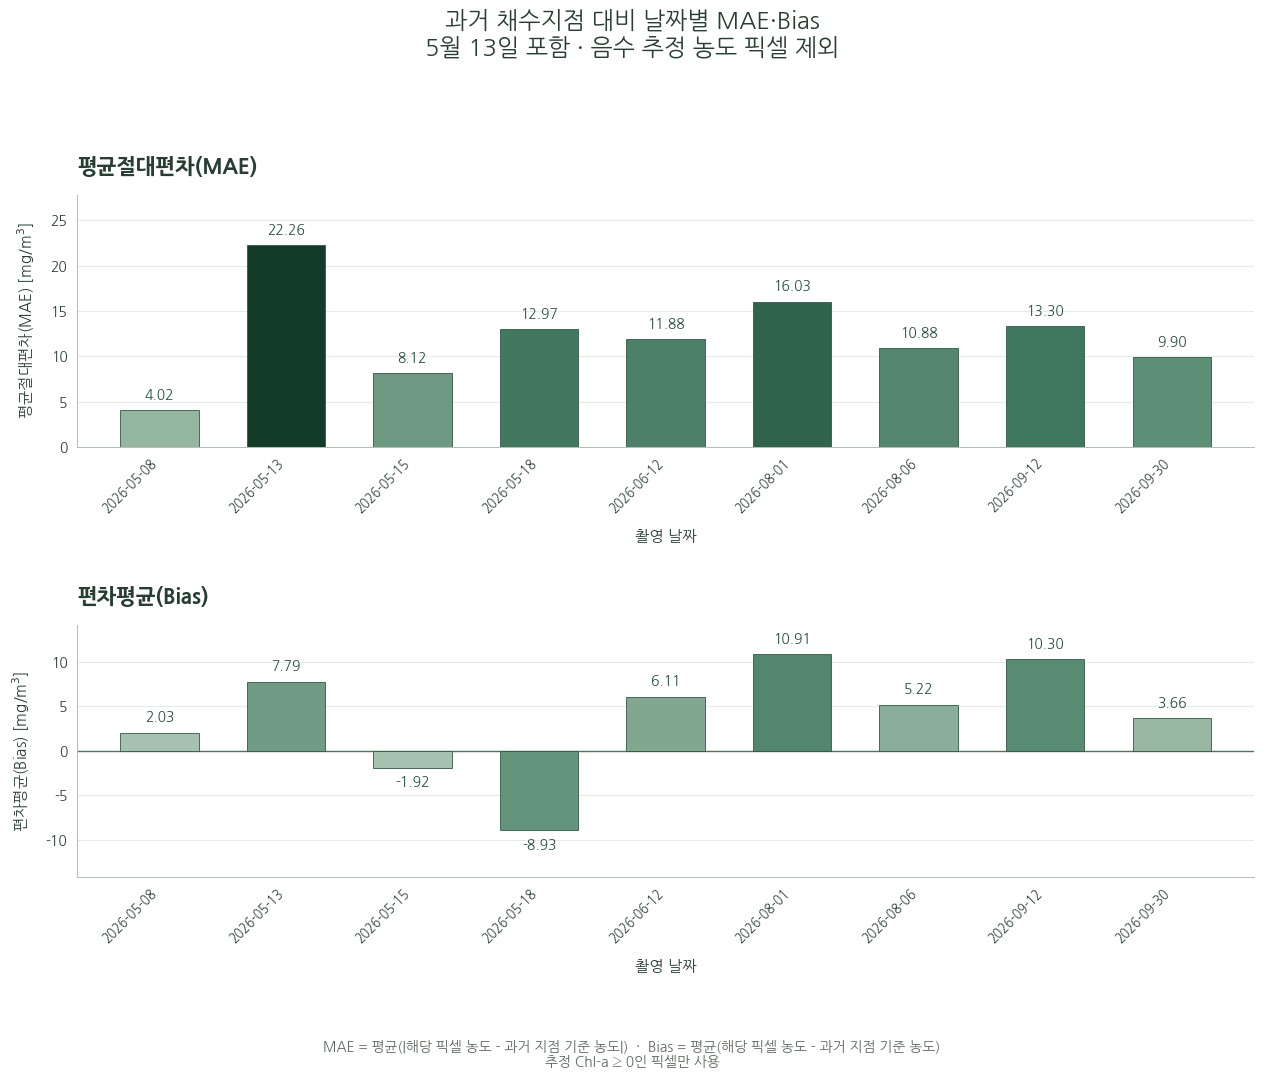

과거 기준 5월 13일 포함 그래프·CSV 저장 완료


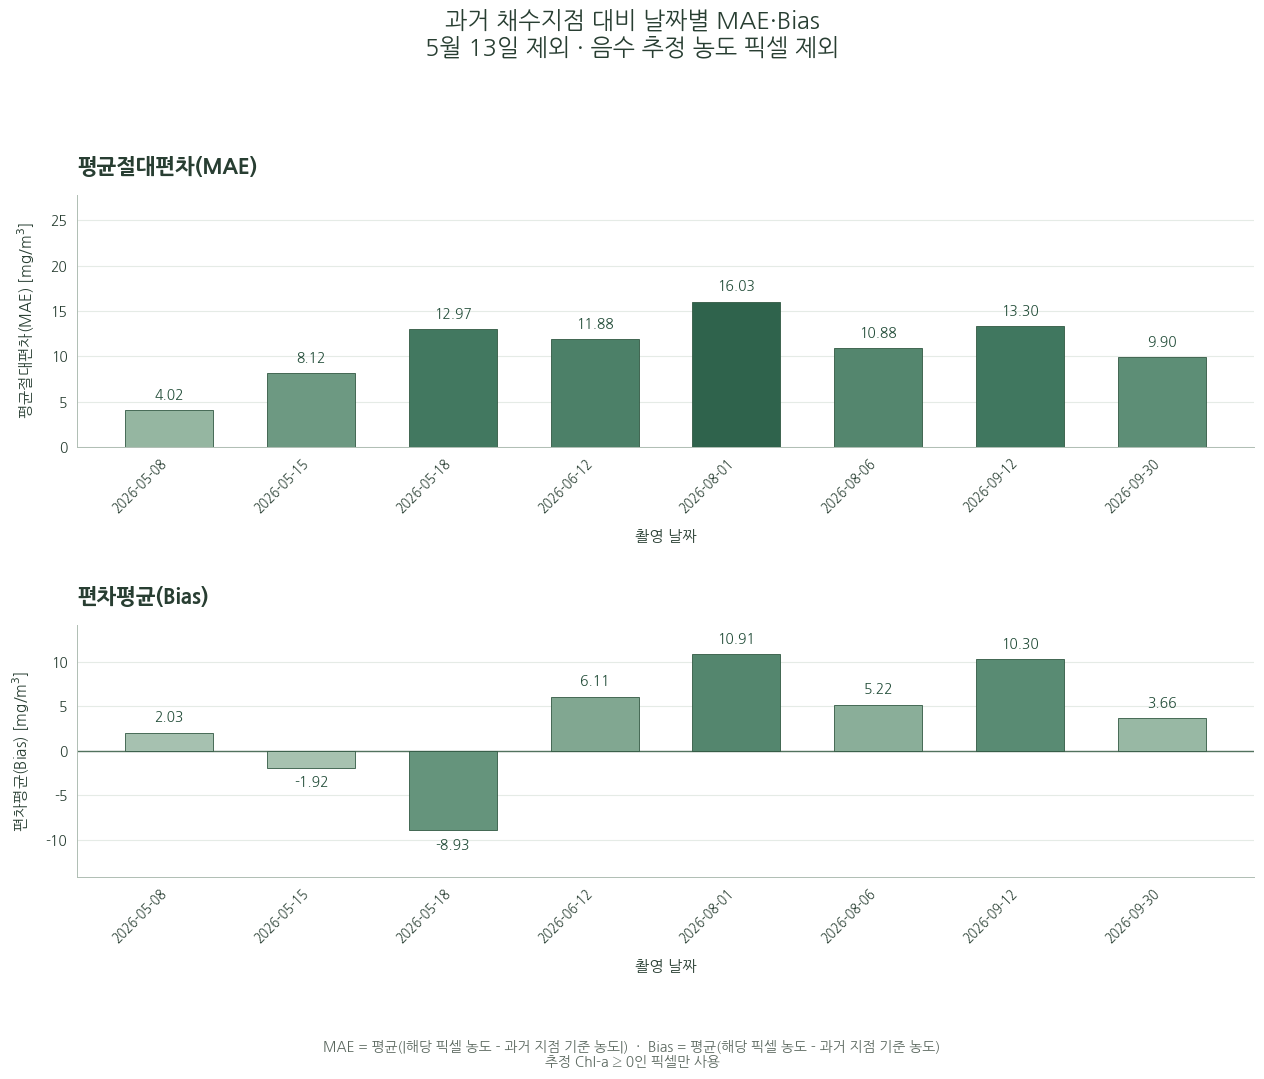

과거 기준 5월 13일 제외 그래프·CSV 저장 완료

과거 채수지점 기준 전체 저장 완료
버전별 PNG 한 장에 MAE와 Bias가 함께 들어갑니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from pathlib import Path
from IPython.display import display
from google.colab import files


# =========================================================
# 1. 과거 채수지점 분석·저장 설정
# =========================================================

SITE_LABEL = "과거 채수지점"
MANIFEST_FILENAME = "픽셀자료_저장목록_과거기준.csv"

EXCLUDE_DATE = "2026-05-13"

if "OUTPUT_DIR" not in globals():
    raise RuntimeError(
        "OUTPUT_DIR이 정의되어 있지 않습니다. "
        "과거 지점 분석 초기화 단계를 먼저 실행해 주세요."
    )

pixel_data_dir = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

graph_dir = (
    Path(OUTPUT_DIR)
    / "MAE_Bias_음수제외_초록색_과거기준"
)

manifest_path = (
    pixel_data_dir
    / MANIFEST_FILENAME
)

plt.rcParams["axes.unicode_minus"] = False


# =========================================================
# 2. 저장목록 불러오기
# =========================================================

if not manifest_path.exists():
    raise FileNotFoundError(
        f"과거 기준 픽셀자료 저장목록이 없습니다: {manifest_path}\n"
        "OUTPUT_DIR과 과거 기준 픽셀자료 저장 여부를 확인해 주세요."
    )

manifest = pd.read_csv(
    manifest_path,
    encoding="utf-8-sig"
)

required_manifest_columns = [
    "촬영시각_KST",
    "영상명",
    "CSV파일명",
    "분석픽셀수",
    "기준픽셀추정_Chla_mg_m3"
]

missing_columns = [
    column
    for column in required_manifest_columns
    if column not in manifest.columns
]

if missing_columns:
    raise ValueError(
        "저장목록에 필요한 열이 없습니다: "
        + ", ".join(missing_columns)
    )

if manifest.empty:
    raise ValueError(
        "저장된 과거 기준 픽셀자료가 없습니다."
    )

# 기준지점 열이 있으면 과거 지점 자료인지 확인
if "기준지점" in manifest.columns:
    if not manifest["기준지점"].eq(SITE_LABEL).all():
        raise ValueError(
            "저장목록에 과거 채수지점이 아닌 자료가 "
            "포함되어 있습니다."
        )

manifest = (
    manifest
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

if manifest.duplicated(
    ["촬영시각_KST", "영상명"]
).any():
    raise ValueError(
        "저장목록에 중복 영상이 있습니다."
    )


# =========================================================
# 3. 날짜·영상별 MAE와 Bias 계산
# =========================================================

records = []

for number, (_, item) in enumerate(
    manifest.iterrows(),
    start=1
):
    csv_path = (
        pixel_data_dir
        / item["CSV파일명"]
    )

    print(
        f"[{number}/{len(manifest)}] "
        f"{item['촬영시각_KST']} | "
        f"{item['영상명']}"
    )

    if not csv_path.exists():
        raise FileNotFoundError(
            f"픽셀자료가 없습니다: {csv_path.name}"
        )

    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    required_columns = [
        "픽셀열",
        "픽셀행",
        "추정_Chla_mg_m3",
        "편차_mg_m3"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{csv_path.name}에 필요한 열이 없습니다: "
            + ", ".join(missing_columns)
        )

    if df.empty:
        raise ValueError(
            f"{csv_path.name}에 분석 픽셀이 없습니다."
        )

    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            f"{csv_path.name}에 중복 픽셀이 있습니다."
        )

    # 기준지점 열이 있으면 과거 지점 자료인지 확인
    if "기준지점" in df.columns:
        if not df["기준지점"].eq(SITE_LABEL).all():
            raise ValueError(
                f"{csv_path.name}에 과거 채수지점이 아닌 "
                "자료가 포함되어 있습니다."
            )

    chla = pd.to_numeric(
        df["추정_Chla_mg_m3"],
        errors="coerce"
    )

    deviation = pd.to_numeric(
        df["편차_mg_m3"],
        errors="coerce"
    )

    if not (
        np.isfinite(chla.to_numpy()).all()
        and np.isfinite(deviation.to_numpy()).all()
    ):
        raise ValueError(
            f"{csv_path.name}의 농도 또는 편차에 "
            "결측·무한대가 있습니다."
        )

    original_count = len(df)

    if original_count != int(item["분석픽셀수"]):
        raise ValueError(
            f"{csv_path.name}의 픽셀 수가 "
            "저장목록과 다릅니다."
        )

    site_chla = float(
        item["기준픽셀추정_Chla_mg_m3"]
    )

    if not np.isfinite(site_chla):
        raise ValueError(
            f"{csv_path.name}의 과거 지점 기준 농도가 "
            "유효하지 않습니다."
        )

    # 픽셀자료와 저장목록의 기준 농도 일치 확인
    if "기준픽셀추정_Chla_mg_m3" in df.columns:
        saved_site = pd.to_numeric(
            df["기준픽셀추정_Chla_mg_m3"],
            errors="coerce"
        ).to_numpy()

        if not (
            np.isfinite(saved_site).all()
            and np.allclose(
                saved_site,
                site_chla,
                rtol=1e-10,
                atol=1e-10
            )
        ):
            raise ValueError(
                f"{csv_path.name}의 기준 농도가 "
                "저장목록과 일치하지 않습니다."
            )

    # 편차 = 해당 픽셀 농도 - 과거 지점 기준 농도
    if not np.allclose(
        deviation.to_numpy(),
        (chla - site_chla).to_numpy(),
        rtol=1e-8,
        atol=1e-8
    ):
        raise ValueError(
            f"{csv_path.name}의 편차가 "
            "'해당 픽셀 농도 - 과거 지점 기준 농도'와 "
            "일치하지 않습니다."
        )

    # 추정 농도가 음수인 픽셀만 제외
    # 편차가 음수인 픽셀은 유지
    negative_mask = chla.lt(0)
    retained_mask = chla.ge(0)

    negative_count = int(
        negative_mask.sum()
    )

    retained_count = int(
        retained_mask.sum()
    )

    record = {
        "촬영시각_KST": item["촬영시각_KST"],
        "영상명": item["영상명"],
        "기준지점": SITE_LABEL,
        "촬영날짜": str(item["촬영시각_KST"])[:10],
        "원래픽셀수": original_count,
        "음수농도픽셀수": negative_count,
        "음수농도픽셀비율_pct":
            negative_count / original_count * 100,
        "음수제외_픽셀수": retained_count,
        "기준픽셀추정_Chla_mg_m3": site_chla,
        "평균절대편차_MAE_mg_m3": np.nan,
        "편차평균_Bias_mg_m3": np.nan,
        "분석상태": ""
    }

    if "영상_ID" in manifest.columns:
        record["영상_ID"] = item["영상_ID"]

    if site_chla < 0:
        record["분석상태"] = (
            "미계산: 기준 농도 음수"
        )

    elif retained_count == 0:
        record["분석상태"] = (
            "미계산: 음수 제외 후 픽셀 없음"
        )

    else:
        selected_deviation = deviation.loc[
            retained_mask
        ]

        record["평균절대편차_MAE_mg_m3"] = float(
            selected_deviation.abs().mean()
        )

        record["편차평균_Bias_mg_m3"] = float(
            selected_deviation.mean()
        )

        record["분석상태"] = "정상"

    records.append(record)

    print(
        f"  원래 {original_count:,}개"
        f" / 음수 농도 {negative_count:,}개"
        f" / 남은 픽셀 {retained_count:,}개"
    )


# =========================================================
# 4. 포함·제외 결과 표 생성
# =========================================================

deviation_metrics_table = (
    pd.DataFrame(records)
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

# 과거 지점 결과를 별도 변수에도 보관
past_deviation_metrics_table = (
    deviation_metrics_table.copy()
)

table_with_may13 = (
    deviation_metrics_table.copy()
)

table_without_may13 = (
    deviation_metrics_table.loc[
        deviation_metrics_table["촬영날짜"].ne(
            EXCLUDE_DATE
        )
    ]
    .copy()
    .reset_index(drop=True)
)

if not deviation_metrics_table["촬영날짜"].eq(
    EXCLUDE_DATE
).any():
    print(
        f"\n주의: 저장목록에 {EXCLUDE_DATE} 영상이 없습니다. "
        "포함·제외 버전의 데이터가 같습니다."
    )

format_settings = {
    "원래픽셀수": "{:,.0f}",
    "음수농도픽셀수": "{:,.0f}",
    "음수농도픽셀비율_pct": "{:.2f}",
    "음수제외_픽셀수": "{:,.0f}",
    "기준픽셀추정_Chla_mg_m3": "{:.3f}",
    "평균절대편차_MAE_mg_m3": "{:.3f}",
    "편차평균_Bias_mg_m3": "{:.3f}"
}

display_columns = [
    column
    for column in deviation_metrics_table.columns
    if column not in ["영상_ID", "촬영날짜"]
]

print("\n과거 채수지점 기준: 5월 13일 포함 결과")

display(
    table_with_may13[display_columns]
    .style
    .format(
        format_settings,
        na_rep="—"
    )
)

print("\n과거 채수지점 기준: 5월 13일 제외 결과")

display(
    table_without_may13[display_columns]
    .style
    .format(
        format_settings,
        na_rep="—"
    )
)


# =========================================================
# 5. 그래프 색상·축 설정
# =========================================================

GREEN_PALETTE = [
    "#B8CDBE",
    "#91B39E",
    "#65947C",
    "#3F765E",
    "#245640",
    "#123B2A"
]

GREEN_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "refined_green",
    GREEN_PALETTE,
    N=256
)

TEXT_COLOR = "#283E32"
VALUE_COLOR = "#244E3A"
BAR_EDGE_COLOR = "#315842"

GRID_COLOR = "#E5EBE6"
AXIS_COLOR = "#AFBDB3"

all_mae = deviation_metrics_table[
    "평균절대편차_MAE_mg_m3"
].to_numpy(dtype=float)

all_bias = deviation_metrics_table[
    "편차평균_Bias_mg_m3"
].to_numpy(dtype=float)

finite_mae = all_mae[
    np.isfinite(all_mae)
]

finite_bias = all_bias[
    np.isfinite(all_bias)
]

magnitude_values = np.concatenate([
    finite_mae,
    np.abs(finite_bias)
])

COLOR_MAX = (
    max(float(magnitude_values.max()), 1e-12)
    if len(magnitude_values)
    else 1.0
)

GREEN_NORM = mcolors.Normalize(
    vmin=0,
    vmax=COLOR_MAX
)

MAE_YMAX = (
    max(float(finite_mae.max()) * 1.25, 1.0)
    if len(finite_mae)
    else 1.0
)

BIAS_YMAX = (
    max(float(np.abs(finite_bias).max()) * 1.30, 1.0)
    if len(finite_bias)
    else 1.0
)


# =========================================================
# 6. 날짜 라벨 생성
# =========================================================

def make_graph_labels(table):
    date_labels = (
        table["촬영날짜"]
        .astype(str)
    )

    duplicate_dates = date_labels.duplicated(
        keep=False
    )

    date_numbers = (
        date_labels
        .groupby(date_labels, sort=False)
        .cumcount()
        .add(1)
    )

    return [
        (
            f"{date}\n({number})"
            if duplicated
            else date
        )
        for date, number, duplicated in zip(
            date_labels,
            date_numbers,
            duplicate_dates
        )
    ]


# =========================================================
# 7. MAE·Bias 통합 그래프 생성
# =========================================================

def create_combined_graph(table, version_title):
    if table.empty:
        return None

    graph_labels = make_graph_labels(table)
    x = np.arange(len(table))

    mae_values = table[
        "평균절대편차_MAE_mg_m3"
    ].to_numpy(dtype=float)

    bias_values = table[
        "편차평균_Bias_mg_m3"
    ].to_numpy(dtype=float)

    figure_width = max(
        13,
        len(table) * 0.72
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(figure_width, 11),
        sharex=False
    )

    fig.patch.set_facecolor("white")

    graph_settings = [
        (
            axes[0],
            mae_values,
            "평균절대편차(MAE)",
            r"평균절대편차(MAE) [mg/m$^{3}$]"
        ),
        (
            axes[1],
            bias_values,
            "편차평균(Bias)",
            r"편차평균(Bias) [mg/m$^{3}$]"
        )
    ]

    for ax, values, title, ylabel in graph_settings:
        ax.set_facecolor("white")

        valid = np.isfinite(values)

        bar_colors = GREEN_CMAP(
            GREEN_NORM(
                np.abs(values[valid])
            )
        )

        ax.bar(
            x[valid],
            values[valid],
            width=0.62,
            color=bar_colors,
            edgecolor=BAR_EDGE_COLOR,
            linewidth=0.6,
            zorder=3
        )

        # 미계산 날짜는 글자 없이 빈자리 유지
        for position, value in zip(
            x[valid],
            values[valid]
        ):
            ax.annotate(
                f"{value:.2f}",
                xy=(position, value),
                xytext=(
                    0,
                    6 if value >= 0 else -6
                ),
                textcoords="offset points",
                ha="center",
                va=(
                    "bottom"
                    if value >= 0
                    else "top"
                ),
                fontsize=10,
                color=VALUE_COLOR
            )

        ax.set_title(
            title,
            loc="left",
            fontsize=15,
            color=TEXT_COLOR,
            fontweight="bold",
            pad=16
        )

        ax.set_ylabel(
            ylabel,
            fontsize=11,
            color=TEXT_COLOR,
            labelpad=10
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            graph_labels,
            rotation=45,
            ha="right",
            fontsize=9
        )

        ax.set_xlabel(
            "촬영 날짜",
            fontsize=11,
            color=TEXT_COLOR,
            labelpad=10
        )

        ax.set_xlim(
            -0.65,
            len(table) - 0.35
        )

        ax.set_axisbelow(True)

        ax.grid(
            axis="y",
            color=GRID_COLOR,
            linewidth=0.8
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.spines["left"].set_color(AXIS_COLOR)
        ax.spines["bottom"].set_color(AXIS_COLOR)

        ax.spines["left"].set_linewidth(0.7)
        ax.spines["bottom"].set_linewidth(0.7)

        ax.tick_params(
            axis="both",
            length=0,
            colors=TEXT_COLOR,
            pad=7
        )

    axes[0].set_ylim(
        0,
        MAE_YMAX
    )

    axes[1].set_ylim(
        -BIAS_YMAX,
        BIAS_YMAX
    )

    axes[1].axhline(
        0,
        color="#52725E",
        linewidth=1.0,
        zorder=2
    )

    fig.suptitle(
        f"{SITE_LABEL} 대비 날짜별 MAE·Bias\n"
        f"{version_title} · 음수 추정 농도 픽셀 제외",
        fontsize=17,
        color=TEXT_COLOR,
        y=0.98
    )

    fig.text(
        0.5,
        0.02,
        "MAE = 평균(|해당 픽셀 농도 - 과거 지점 기준 농도|)"
        "  ·  Bias = 평균(해당 픽셀 농도 - 과거 지점 기준 농도)\n"
        "추정 Chl-a ≥ 0인 픽셀만 사용",
        ha="center",
        fontsize=10,
        color="#5B685F"
    )

    fig.tight_layout(
        rect=[0.01, 0.09, 0.99, 0.92],
        h_pad=3.0
    )

    return fig


# =========================================================
# 8. 포함·제외 그래프 및 CSV 저장
# =========================================================

graph_dir.mkdir(
    parents=True,
    exist_ok=True
)

version_settings = [
    (
        table_with_may13,
        "5월 13일 포함",
        "5월13일포함"
    ),
    (
        table_without_may13,
        "5월 13일 제외",
        "5월13일제외"
    )
]

saved_paths = []

for table, version_title, filename_suffix in version_settings:
    csv_path = (
        graph_dir
        / (
            "MAE_Bias_과거기준_음수농도제외_"
            f"{filename_suffix}.csv"
        )
    )

    table.to_csv(
        csv_path,
        index=False,
        encoding="utf-8-sig"
    )

    saved_paths.append(csv_path)

    if table.empty:
        print(
            f"\n{version_title}: 영상이 없어 "
            "그래프 생성을 생략합니다."
        )
        continue

    fig = create_combined_graph(
        table,
        version_title
    )

    graph_path = (
        graph_dir
        / (
            "MAE_Bias_과거기준_음수농도제외_초록색_"
            f"{filename_suffix}.png"
        )
    )

    fig.savefig(
        graph_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    saved_paths.append(graph_path)

    plt.show()
    plt.close(fig)

    print(
        f"과거 기준 {version_title} 그래프·CSV 저장 완료"
    )


# =========================================================
# 9. 결과 다운로드
# =========================================================

print("\n과거 채수지점 기준 전체 저장 완료")
print("버전별 PNG 한 장에 MAE와 Bias가 함께 들어갑니다.")

for path in saved_paths:
    files.download(str(path))

비율 계산

[1/8] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
[2/8] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE
[3/8] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE
[4/8] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE
[5/8] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE
[6/8] 2026-08-06 11:17 | 20260806T020649_20260806T021309_T52SDE
[7/8] 2026-09-12 11:17 | 20260912T021121_20260912T021121_T52SDE
[8/8] 2026-09-30 11:17 | 20260930T020651_20260930T021242_T52SDE

과거 채수지점 기준 음수 농도 제외 후 유효수면 현황


,촬영시각_KST,영상명,기준지점,촬영날짜,원래픽셀수,음수농도픽셀수,유효수면픽셀수,전체유효수면면적_km2,기준픽셀추정_Chla_mg_m3,분석상태,영상_ID
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,2026-05-08,"28,413",204,"28,209",11.2926,17.754,정상,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE
1,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,2026-05-15,"28,672","1,892","26,780",10.7206,24.540,정상,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20260515T021122_T52SDE
2,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,과거 채수지점,2026-05-18,"31,257","2,626","28,631",11.4616,31.501,정상,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20260518T021212_T52SDE
3,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,과거 채수지점,2026-06-12,"33,102",363,"32,739",13.1061,42.772,정상,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20260612T021313_T52SDE
4,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,과거 채수지점,2026-08-01,"32,088",769,"31,319",12.5376,41.165,정상,COPERNICUS/S2_SR_HARMONIZED/20260801T020651_20260801T021347_T52SDE
5,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,과거 채수지점,2026-08-06,"28,853","1,149","27,704",11.0905,44.374,정상,COPERNICUS/S2_SR_HARMONIZED/20260806T020649_20260806T021309_T52SDE
6,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,과거 채수지점,2026-09-12,"32,247","1,377","30,870",12.3579,23.197,정상,COPERNICUS/S2_SR_HARMONIZED/20260912T021121_20260912T021121_T52SDE
7,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,과거 채수지점,2026-09-30,"33,427",986,"32,441",12.9868,49.608,정상,COPERNICUS/S2_SR_HARMONIZED/20260930T020651_20260930T021242_T52SDE



과거 채수지점 기준 절대편차 구간별 면적 통계


,촬영시각_KST,영상명,기준지점,절대편차구간,픽셀수,면적_m2,면적_km2,면적비율_pct,분석상태,영상_ID
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,0~5 이하,"22,284","8,920,723.22",8.9207,79.00,정상,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE
1,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,5 초과~10 이하,"4,021","1,609,685.66",1.6097,14.25,정상,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE
2,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,10 초과~15 이하,774,"309,847.46",0.3098,2.74,정상,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE
3,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,과거 채수지점,15 초과,"1,130","452,361.47",0.4524,4.01,정상,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE
4,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,0~5 이하,"12,236","4,898,311.70",4.8983,45.69,정상,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20260515T021122_T52SDE
5,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,5 초과~10 이하,"6,842","2,738,987.28",2.7390,25.55,정상,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20260515T021122_T52SDE
6,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,10 초과~15 이하,"3,636","1,455,562.25",1.4556,13.58,정상,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20260515T021122_T52SDE
7,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,과거 채수지점,15 초과,"4,066","1,627,700.17",1.6277,15.18,정상,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20260515T021122_T52SDE
8,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,과거 채수지점,0~5 이하,"5,161","2,066,050.48",2.0661,18.03,정상,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20260518T021212_T52SDE
9,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,과거 채수지점,5 초과~10 이하,"7,320","2,930,340.60",2.9303,25.57,정상,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20260518T021212_T52SDE


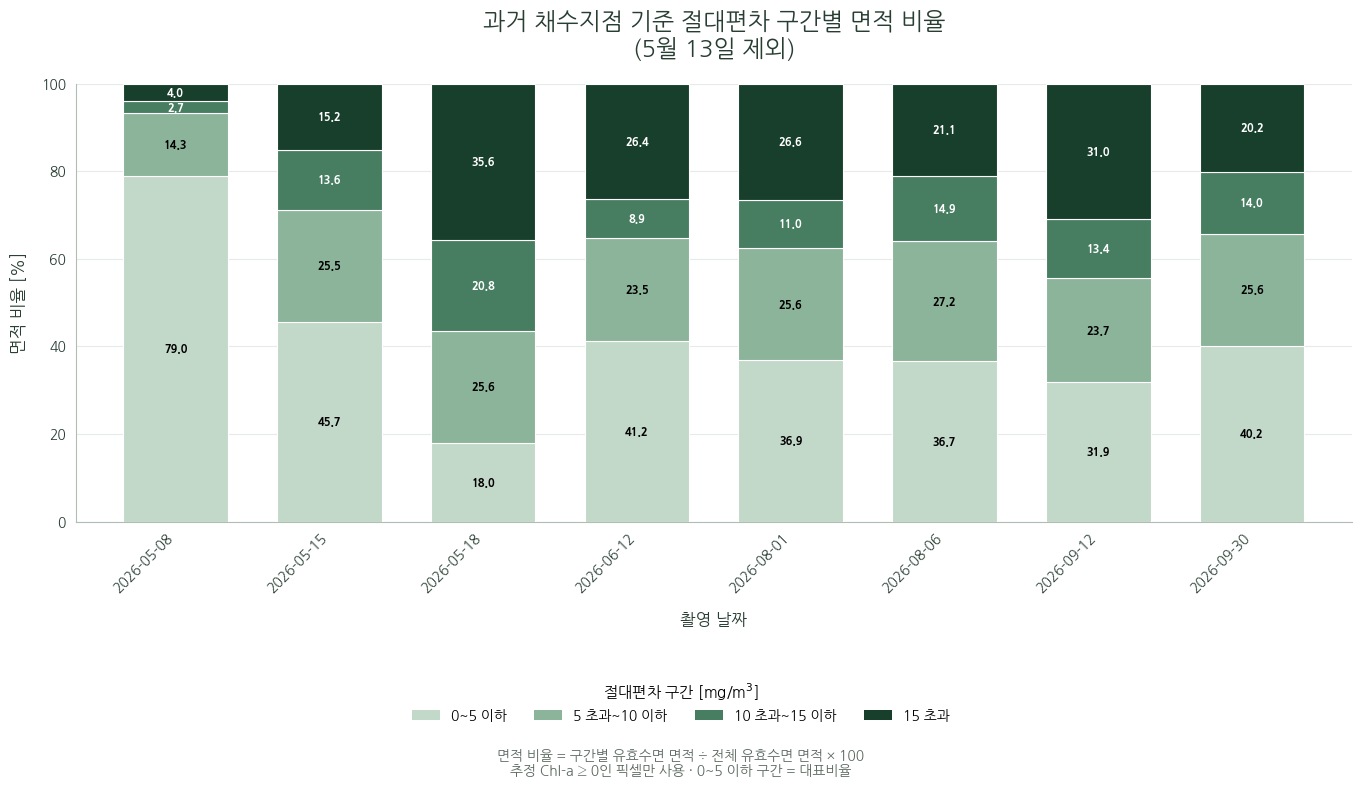

과거 기준 절대편차 구간별 그래프·CSV 저장 완료


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from pathlib import Path
from IPython.display import display
from google.colab import files


# =========================================================
# 1. 과거 채수지점 분석 설정
# =========================================================

SITE_LABEL = "과거 채수지점"
MANIFEST_FILENAME = "픽셀자료_저장목록_과거기준.csv"

EXCLUDE_DATE = "2026-05-13"

if "OUTPUT_DIR" not in globals():
    raise RuntimeError(
        "OUTPUT_DIR이 정의되어 있지 않습니다. "
        "과거 지점 분석 초기화 단계를 먼저 실행해 주세요."
    )

pixel_data_dir = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

graph_dir = (
    Path(OUTPUT_DIR)
    / "절대편차구간_음수제외_과거기준"
)

manifest_path = (
    pixel_data_dir
    / MANIFEST_FILENAME
)

plt.rcParams["axes.unicode_minus"] = False


# =========================================================
# 2. 저장목록 불러오기
# =========================================================

if not manifest_path.exists():
    raise FileNotFoundError(
        f"과거 기준 저장목록이 없습니다: {manifest_path}\n"
        "OUTPUT_DIR과 과거 기준 픽셀자료 저장 여부를 확인해 주세요."
    )

manifest = pd.read_csv(
    manifest_path,
    encoding="utf-8-sig"
)

required_manifest_columns = [
    "촬영시각_KST",
    "영상명",
    "CSV파일명",
    "분석픽셀수",
    "기준픽셀추정_Chla_mg_m3"
]

missing_columns = [
    column
    for column in required_manifest_columns
    if column not in manifest.columns
]

if missing_columns:
    raise ValueError(
        "저장목록에 필요한 열이 없습니다: "
        + ", ".join(missing_columns)
    )

if manifest.empty:
    raise ValueError(
        "저장된 과거 기준 픽셀자료가 없습니다."
    )

# 기준지점 정보가 있으면 과거 지점 자료인지 확인
if "기준지점" in manifest.columns:
    if not manifest["기준지점"].eq(SITE_LABEL).all():
        raise ValueError(
            "저장목록에 과거 채수지점이 아닌 자료가 "
            "포함되어 있습니다."
        )

manifest["촬영날짜"] = (
    manifest["촬영시각_KST"]
    .astype(str)
    .str.slice(0, 10)
)

# 5월 13일 제외
manifest = (
    manifest.loc[
        manifest["촬영날짜"].ne(EXCLUDE_DATE)
    ]
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

if manifest.empty:
    raise ValueError(
        "5월 13일 제외 후 분석할 영상이 없습니다."
    )

if manifest.duplicated(
    ["촬영시각_KST", "영상명"]
).any():
    raise ValueError(
        "저장목록에 중복 영상이 있습니다."
    )


# =========================================================
# 3. 구간·색상 설정
# =========================================================

INTERVAL_ORDER = [
    "0~5 이하",
    "5 초과~10 이하",
    "10 초과~15 이하",
    "15 초과"
]

INTERVAL_COLORS = {
    "0~5 이하": "#C2D8C8",
    "5 초과~10 이하": "#8BB49A",
    "10 초과~15 이하": "#477E61",
    "15 초과": "#173F2C"
}

INTERVAL_TEXT_COLORS = {
    "0~5 이하": "black",
    "5 초과~10 이하": "black",
    "10 초과~15 이하": "white",
    "15 초과": "white"
}


# =========================================================
# 4. 영상별 절대편차 구간 통계
# =========================================================

detail_records = []
summary_records = []

for number, (_, item) in enumerate(
    manifest.iterrows(),
    start=1
):
    print(
        f"[{number}/{len(manifest)}] "
        f"{item['촬영시각_KST']} | "
        f"{item['영상명']}"
    )

    csv_path = (
        pixel_data_dir
        / item["CSV파일명"]
    )

    if not csv_path.exists():
        raise FileNotFoundError(
            f"픽셀자료가 없습니다: {csv_path.name}"
        )

    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    required_columns = [
        "픽셀열",
        "픽셀행",
        "추정_Chla_mg_m3",
        "편차_mg_m3",
        "픽셀면적_m2"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{csv_path.name}에 필요한 열이 없습니다: "
            + ", ".join(missing_columns)
        )

    if df.empty:
        raise ValueError(
            f"{csv_path.name}에 분석 픽셀이 없습니다."
        )

    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            f"{csv_path.name}에 중복 픽셀이 있습니다."
        )

    if "기준지점" in df.columns:
        if not df["기준지점"].eq(SITE_LABEL).all():
            raise ValueError(
                f"{csv_path.name}에 과거 채수지점이 아닌 "
                "자료가 포함되어 있습니다."
            )

    chla = pd.to_numeric(
        df["추정_Chla_mg_m3"],
        errors="coerce"
    )

    deviation = pd.to_numeric(
        df["편차_mg_m3"],
        errors="coerce"
    )

    pixel_area = pd.to_numeric(
        df["픽셀면적_m2"],
        errors="coerce"
    )

    if not (
        np.isfinite(chla.to_numpy()).all()
        and np.isfinite(deviation.to_numpy()).all()
        and np.isfinite(pixel_area.to_numpy()).all()
        and pixel_area.gt(0).all()
    ):
        raise ValueError(
            f"{csv_path.name}의 농도·편차·면적에 "
            "결측 또는 비정상 값이 있습니다."
        )

    if len(df) != int(item["분석픽셀수"]):
        raise ValueError(
            f"{csv_path.name}의 픽셀 수가 "
            "저장목록과 다릅니다."
        )

    site_chla = float(
        item["기준픽셀추정_Chla_mg_m3"]
    )

    if not np.isfinite(site_chla):
        raise ValueError(
            f"{csv_path.name}의 과거 지점 기준 농도가 "
            "유효하지 않습니다."
        )

    # 기준 농도 정보 일치 확인
    if "기준픽셀추정_Chla_mg_m3" in df.columns:
        saved_site = pd.to_numeric(
            df["기준픽셀추정_Chla_mg_m3"],
            errors="coerce"
        ).to_numpy()

        if not (
            np.isfinite(saved_site).all()
            and np.allclose(
                saved_site,
                site_chla,
                rtol=1e-10,
                atol=1e-10
            )
        ):
            raise ValueError(
                f"{csv_path.name}의 기준 농도가 "
                "저장목록과 일치하지 않습니다."
            )

    # 편차 = 해당 픽셀 농도 - 과거 지점 기준 농도
    if not np.allclose(
        deviation.to_numpy(),
        (chla - site_chla).to_numpy(),
        rtol=1e-8,
        atol=1e-8
    ):
        raise ValueError(
            f"{csv_path.name}의 편차가 "
            "'해당 픽셀 농도 - 과거 지점 기준 농도'와 "
            "일치하지 않습니다."
        )

    # 추정 농도가 0 이상인 픽셀만 유효수면으로 사용
    valid_water_mask = chla.ge(0)

    valid_count = int(
        valid_water_mask.sum()
    )

    negative_count = int(
        chla.lt(0).sum()
    )

    valid_area_m2 = float(
        pixel_area.loc[valid_water_mask].sum()
    )

    status = "정상"

    if site_chla < 0:
        status = "미계산: 기준 농도 음수"

    elif valid_count == 0:
        status = "미계산: 유효수면 없음"

    summary_record = {
        "촬영시각_KST": item["촬영시각_KST"],
        "영상명": item["영상명"],
        "기준지점": SITE_LABEL,
        "촬영날짜": item["촬영날짜"],
        "원래픽셀수": len(df),
        "음수농도픽셀수": negative_count,
        "유효수면픽셀수": valid_count,
        "전체유효수면면적_km2":
            valid_area_m2 / 1_000_000,
        "기준픽셀추정_Chla_mg_m3": site_chla,
        "분석상태": status
    }

    if "영상_ID" in manifest.columns:
        summary_record["영상_ID"] = item["영상_ID"]

    summary_records.append(summary_record)

    absolute_deviation = deviation.abs()

    conditions = [
        absolute_deviation.le(5),

        absolute_deviation.gt(5)
        & absolute_deviation.le(10),

        absolute_deviation.gt(10)
        & absolute_deviation.le(15),

        absolute_deviation.gt(15)
    ]

    image_records = []

    for label, condition in zip(
        INTERVAL_ORDER,
        conditions
    ):
        if status == "정상":
            selected = (
                valid_water_mask
                & condition
            )

            count = int(
                selected.sum()
            )

            area_m2 = float(
                pixel_area.loc[selected].sum()
            )

            area_ratio = (
                area_m2 / valid_area_m2 * 100
            )

        else:
            count = np.nan
            area_m2 = np.nan
            area_ratio = np.nan

        interval_record = {
            "촬영시각_KST": item["촬영시각_KST"],
            "영상명": item["영상명"],
            "기준지점": SITE_LABEL,
            "절대편차구간": label,
            "픽셀수": count,
            "면적_m2": area_m2,
            "면적_km2": area_m2 / 1_000_000,
            "면적비율_pct": area_ratio,
            "분석상태": status
        }

        if "영상_ID" in manifest.columns:
            interval_record["영상_ID"] = item["영상_ID"]

        image_records.append(interval_record)

    # 구간 합계 검증
    if status == "정상":
        if sum(
            record["픽셀수"]
            for record in image_records
        ) != valid_count:
            raise ValueError(
                f"{csv_path.name}: 구간별 픽셀 수 합계 오류"
            )

        if not np.isclose(
            sum(
                record["면적_m2"]
                for record in image_records
            ),
            valid_area_m2,
            rtol=1e-9,
            atol=0.01
        ):
            raise ValueError(
                f"{csv_path.name}: 구간별 면적 합계 오류"
            )

    detail_records.extend(image_records)


# =========================================================
# 5. 결과 표 정리
# =========================================================

absolute_deviation_detail = pd.DataFrame(
    detail_records
)

absolute_deviation_summary = pd.DataFrame(
    summary_records
)

# 과거 지점 결과 별도 보관
past_absolute_deviation_detail = (
    absolute_deviation_detail.copy()
)

past_absolute_deviation_summary = (
    absolute_deviation_summary.copy()
)

print("\n과거 채수지점 기준 음수 농도 제외 후 유효수면 현황")

display(
    absolute_deviation_summary.style
    .format(
        {
            "원래픽셀수": "{:,.0f}",
            "음수농도픽셀수": "{:,.0f}",
            "유효수면픽셀수": "{:,.0f}",
            "전체유효수면면적_km2": "{:.4f}",
            "기준픽셀추정_Chla_mg_m3": "{:.3f}"
        },
        na_rep="—"
    )
)

print("\n과거 채수지점 기준 절대편차 구간별 면적 통계")

display(
    absolute_deviation_detail.style
    .format(
        {
            "픽셀수": "{:,.0f}",
            "면적_m2": "{:,.2f}",
            "면적_km2": "{:.4f}",
            "면적비율_pct": "{:.2f}"
        },
        na_rep="—"
    )
)


# =========================================================
# 6. 그래프 데이터와 날짜 라벨
# =========================================================

image_keys = absolute_deviation_summary[[
    "촬영시각_KST",
    "영상명",
    "촬영날짜"
]].copy()

date_labels = image_keys["촬영날짜"]

duplicate_dates = date_labels.duplicated(
    keep=False
)

date_numbers = (
    date_labels
    .groupby(date_labels, sort=False)
    .cumcount()
    .add(1)
)

graph_labels = [
    (
        f"{date}\n({number})"
        if duplicated
        else date
    )
    for date, number, duplicated in zip(
        date_labels,
        date_numbers,
        duplicate_dates
    )
]

ratio_wide = (
    absolute_deviation_detail
    .pivot(
        index=["촬영시각_KST", "영상명"],
        columns="절대편차구간",
        values="면적비율_pct"
    )
    .reindex(columns=INTERVAL_ORDER)
    .reset_index()
)

plot_table = image_keys.merge(
    ratio_wide,
    on=["촬영시각_KST", "영상명"],
    how="left",
    validate="one_to_one"
)

plot_table["그래프표시"] = graph_labels


# =========================================================
# 7. 구간별 면적 비율 누적 막대그래프
# =========================================================

figure_width = max(
    14,
    len(plot_table) * 0.8
)

fig, ax = plt.subplots(
    figsize=(figure_width, 8)
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

x = np.arange(len(plot_table))
bottom = np.zeros(len(plot_table))

for interval in INTERVAL_ORDER:
    values = plot_table[
        interval
    ].to_numpy(dtype=float)

    valid = np.isfinite(values)

    bars = ax.bar(
        x[valid],
        values[valid],
        bottom=bottom[valid],
        width=0.68,
        color=INTERVAL_COLORS[interval],
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    # 면적이 있는 구간에 숫자 표시
    # 미계산 날짜는 글자 없이 빈자리 유지
    for bar, value in zip(
        bars,
        values[valid]
    ):
        if value > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color=INTERVAL_TEXT_COLORS[interval],
                fontweight="bold",
                zorder=5
            )

    bottom[valid] += values[valid]

ax.set_title(
    f"{SITE_LABEL} 기준 절대편차 구간별 면적 비율\n"
    "(5월 13일 제외)",
    fontsize=17,
    color="#283E32",
    pad=20
)

ax.set_xlabel(
    "촬영 날짜",
    fontsize=12,
    color="#283E32",
    labelpad=12
)

ax.set_ylabel(
    "면적 비율 [%]",
    fontsize=12,
    color="#283E32",
    labelpad=10
)

ax.set_xticks(x)

ax.set_xticklabels(
    graph_labels,
    rotation=45,
    ha="right",
    fontsize=10
)

ax.set_ylim(0, 100)

ax.set_xlim(
    -0.65,
    len(plot_table) - 0.35
)

ax.set_axisbelow(True)

ax.grid(
    axis="y",
    color="#E5EBE6",
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#AFBDB3")
ax.spines["bottom"].set_color("#AFBDB3")

ax.tick_params(
    axis="both",
    length=0,
    colors="#283E32",
    pad=7
)

legend_handles = [
    Patch(
        facecolor=INTERVAL_COLORS[label],
        edgecolor="none",
        label=label
    )
    for label in INTERVAL_ORDER
]

fig.legend(
    handles=legend_handles,
    title=r"절대편차 구간 [mg/m$^{3}$]",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.075),
    ncol=4,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

fig.text(
    0.5,
    0.025,
    "면적 비율 = 구간별 유효수면 면적 ÷ 전체 유효수면 면적 × 100\n"
    "추정 Chl-a ≥ 0인 픽셀만 사용 · 0~5 이하 구간 = 대표비율",
    ha="center",
    fontsize=10,
    color="#5B685F"
)

fig.tight_layout(
    rect=[0.01, 0.19, 0.99, 1]
)


# =========================================================
# 8. 그래프·CSV 저장
# =========================================================

graph_dir.mkdir(
    parents=True,
    exist_ok=True
)

graph_path = (
    graph_dir
    / "절대편차구간_면적비율_과거기준_음수제외_5월13일제외.png"
)

detail_csv_path = (
    graph_dir
    / "절대편차구간_상세통계_과거기준_음수제외_5월13일제외.csv"
)

summary_csv_path = (
    graph_dir
    / "절대편차구간_유효수면_과거기준_음수제외_5월13일제외.csv"
)

fig.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

absolute_deviation_detail.to_csv(
    detail_csv_path,
    index=False,
    encoding="utf-8-sig"
)

absolute_deviation_summary.to_csv(
    summary_csv_path,
    index=False,
    encoding="utf-8-sig"
)

plt.show()
plt.close(fig)

print("과거 기준 절대편차 구간별 그래프·CSV 저장 완료")

files.download(str(graph_path))
files.download(str(detail_csv_path))
files.download(str(summary_csv_path))

대표면적 ,대표비율

[1/8] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
[2/8] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE
[3/8] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE
[4/8] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE
[5/8] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE
[6/8] 2026-08-06 11:17 | 20260806T020649_20260806T021309_T52SDE
[7/8] 2026-09-12 11:17 | 20260912T021121_20260912T021121_T52SDE
[8/8] 2026-09-30 11:17 | 20260930T020651_20260930T021242_T52SDE

과거 채수지점 기준 대표면적·대표비율
5월 13일 제외 / 추정 Chl-a가 음수인 픽셀 제외


,촬영시각_KST,영상명,음수농도픽셀수,전체유효수면면적_km2,대표면적_km2,대표비율_pct,분석상태
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,204,11.2926,8.9207,79.00,정상
1,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,"1,892",10.7206,4.8983,45.69,정상
2,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,"2,626",11.4616,2.0661,18.03,정상
3,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,363,13.1061,5.3939,41.16,정상
4,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,769,12.5376,4.6265,36.90,정상
5,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,"1,149",11.0905,4.0745,36.74,정상
6,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,"1,377",12.3579,3.9379,31.87,정상
7,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,986,12.9868,5.2226,40.21,정상


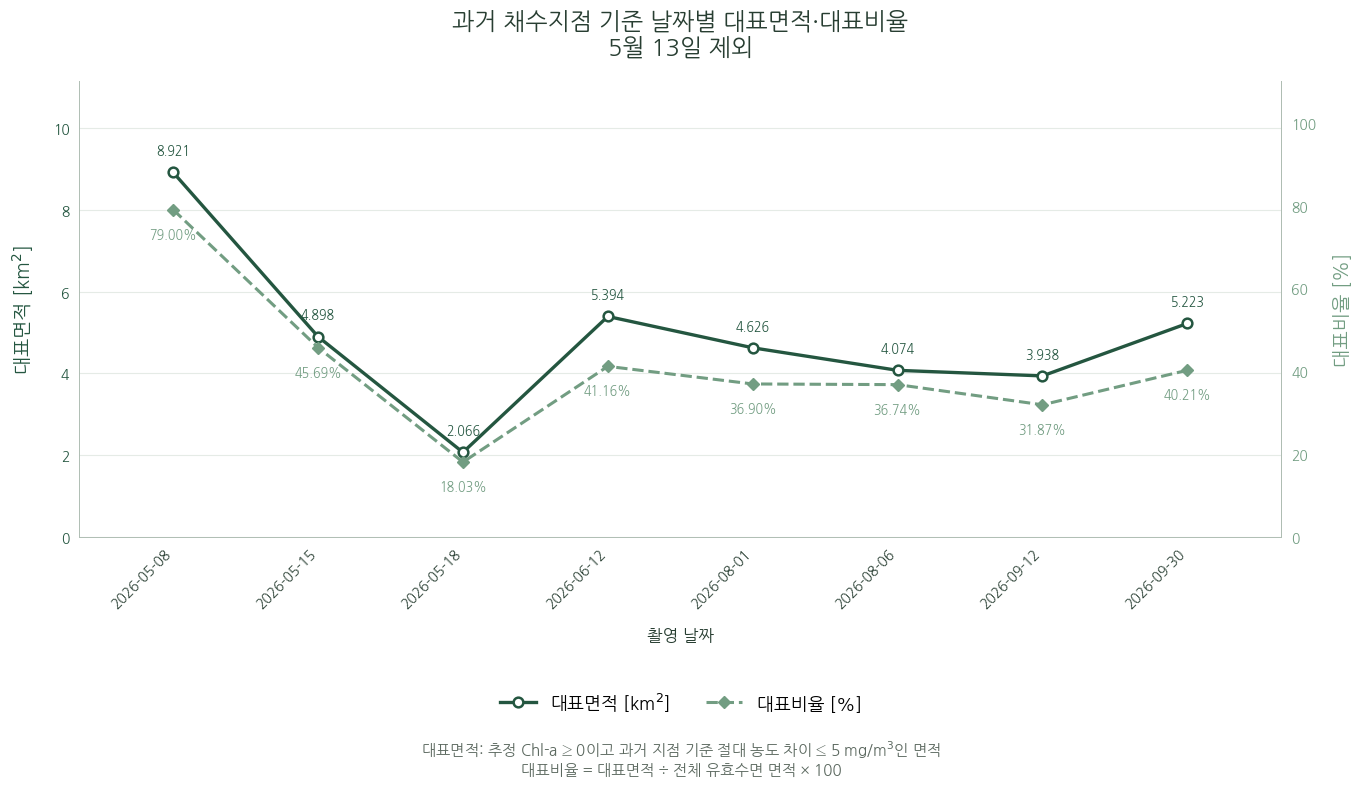


과거 채수지점 기준 대표면적·대표비율 계산 및 저장 완료
ZIP 구성: 꺾은선그래프 PNG 1장 + 결과 CSV 1개


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

from pathlib import Path
from IPython.display import display
from google.colab import files


# =========================================================
# 1. 과거 채수지점 분석 설정
# =========================================================

SITE_LABEL = "과거 채수지점"
MANIFEST_FILENAME = "픽셀자료_저장목록_과거기준.csv"

EXCLUDE_DATE = "2026-05-13"
REPRESENTATIVE_THRESHOLD = 5.0

# 그래프 단위 표시
AREA_UNIT = r"km$^{2}$"
CONCENTRATION_UNIT = r"mg/m$^{3}$"

if "OUTPUT_DIR" not in globals():
    raise RuntimeError(
        "OUTPUT_DIR이 정의되어 있지 않습니다. "
        "과거 지점 분석 초기화 단계를 먼저 실행해 주세요."
    )

pixel_data_dir = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

result_dir = (
    Path(OUTPUT_DIR)
    / "대표면적_대표비율_과거기준"
)

manifest_path = (
    pixel_data_dir
    / MANIFEST_FILENAME
)

plt.rcParams["axes.unicode_minus"] = False


# =========================================================
# 2. 저장목록 불러오기 및 5월 13일 제외
# =========================================================

if not manifest_path.exists():
    raise FileNotFoundError(
        f"과거 기준 저장목록이 없습니다: {manifest_path}\n"
        "OUTPUT_DIR과 과거 기준 픽셀자료 저장 여부를 확인해 주세요."
    )

manifest = pd.read_csv(
    manifest_path,
    encoding="utf-8-sig"
)

required_manifest_columns = [
    "촬영시각_KST",
    "영상명",
    "CSV파일명",
    "분석픽셀수",
    "기준픽셀추정_Chla_mg_m3"
]

missing_columns = [
    column
    for column in required_manifest_columns
    if column not in manifest.columns
]

if missing_columns:
    raise ValueError(
        "저장목록에 필요한 열이 없습니다: "
        + ", ".join(missing_columns)
    )

if manifest.empty:
    raise ValueError(
        "저장된 과거 기준 픽셀자료가 없습니다."
    )

# 기준지점 정보가 있으면 과거 지점 자료인지 확인
if "기준지점" in manifest.columns:
    if not manifest["기준지점"].eq(SITE_LABEL).all():
        raise ValueError(
            "저장목록에 과거 채수지점이 아닌 자료가 "
            "포함되어 있습니다."
        )

manifest["촬영날짜"] = (
    manifest["촬영시각_KST"]
    .astype(str)
    .str.slice(0, 10)
)

manifest = (
    manifest.loc[
        manifest["촬영날짜"].ne(EXCLUDE_DATE)
    ]
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

if manifest.empty:
    raise ValueError(
        "5월 13일 제외 후 분석할 영상이 없습니다."
    )

if manifest.duplicated(
    ["촬영시각_KST", "영상명"]
).any():
    raise ValueError(
        "저장목록에 중복 영상이 있습니다."
    )


# =========================================================
# 3. 대표면적·대표비율 계산
# =========================================================

records = []

for number, (_, item) in enumerate(
    manifest.iterrows(),
    start=1
):
    print(
        f"[{number}/{len(manifest)}] "
        f"{item['촬영시각_KST']} | "
        f"{item['영상명']}"
    )

    csv_path = (
        pixel_data_dir
        / item["CSV파일명"]
    )

    if not csv_path.exists():
        raise FileNotFoundError(
            f"픽셀자료가 없습니다: {csv_path.name}"
        )

    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    required_columns = [
        "픽셀열",
        "픽셀행",
        "추정_Chla_mg_m3",
        "픽셀면적_m2"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{csv_path.name}에 필요한 열이 없습니다: "
            + ", ".join(missing_columns)
        )

    if df.empty:
        raise ValueError(
            f"{csv_path.name}에 픽셀자료가 없습니다."
        )

    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            f"{csv_path.name}에 중복 픽셀이 있습니다."
        )

    if len(df) != int(item["분석픽셀수"]):
        raise ValueError(
            f"{csv_path.name}의 픽셀 수가 "
            "저장목록과 다릅니다."
        )

    if "기준지점" in df.columns:
        if not df["기준지점"].eq(SITE_LABEL).all():
            raise ValueError(
                f"{csv_path.name}에 과거 채수지점이 아닌 "
                "자료가 포함되어 있습니다."
            )

    chla = pd.to_numeric(
        df["추정_Chla_mg_m3"],
        errors="coerce"
    )

    pixel_area = pd.to_numeric(
        df["픽셀면적_m2"],
        errors="coerce"
    )

    if not (
        np.isfinite(chla.to_numpy()).all()
        and np.isfinite(pixel_area.to_numpy()).all()
        and pixel_area.gt(0).all()
    ):
        raise ValueError(
            f"{csv_path.name}의 농도 또는 면적에 "
            "결측·비정상 값이 있습니다."
        )

    site_chla = float(
        item["기준픽셀추정_Chla_mg_m3"]
    )

    if not np.isfinite(site_chla):
        raise ValueError(
            f"{csv_path.name}의 과거 지점 기준 농도가 "
            "유효하지 않습니다."
        )

    # 픽셀자료와 저장목록의 기준 농도 일치 확인
    if "기준픽셀추정_Chla_mg_m3" in df.columns:
        saved_site = pd.to_numeric(
            df["기준픽셀추정_Chla_mg_m3"],
            errors="coerce"
        ).to_numpy()

        if not (
            np.isfinite(saved_site).all()
            and np.allclose(
                saved_site,
                site_chla,
                rtol=1e-10,
                atol=1e-10
            )
        ):
            raise ValueError(
                f"{csv_path.name}의 기준 농도가 "
                "저장목록과 일치하지 않습니다."
            )

    # 전체 유효수면: 추정 Chl-a가 0 이상인 픽셀
    valid_water_mask = chla.ge(0)

    valid_area_m2 = float(
        pixel_area.loc[valid_water_mask].sum()
    )

    record = {
        "촬영시각_KST": item["촬영시각_KST"],
        "영상명": item["영상명"],
        "기준지점": SITE_LABEL,
        "촬영날짜": item["촬영날짜"],
        "음수농도픽셀수": int(chla.lt(0).sum()),
        "유효수면픽셀수": int(valid_water_mask.sum()),
        "전체유효수면면적_km2":
            valid_area_m2 / 1_000_000,
        "기준픽셀추정_Chla_mg_m3": site_chla,
        "대표면적_km2": np.nan,
        "대표비율_pct": np.nan,
        "분석상태": ""
    }

    if "영상_ID" in manifest.columns:
        record["영상_ID"] = item["영상_ID"]

    if site_chla < 0:
        record["분석상태"] = (
            "미계산: 기준 농도 음수"
        )

    elif valid_area_m2 <= 0:
        record["분석상태"] = (
            "미계산: 유효수면 없음"
        )

    else:
        # 반올림하지 않은 원래 농도값으로 판정
        absolute_difference = (
            chla - site_chla
        ).abs()

        representative_mask = (
            valid_water_mask
            & absolute_difference.le(
                REPRESENTATIVE_THRESHOLD
            )
        )

        representative_area_m2 = float(
            pixel_area.loc[
                representative_mask
            ].sum()
        )

        record["대표면적_km2"] = (
            representative_area_m2 / 1_000_000
        )

        record["대표비율_pct"] = (
            representative_area_m2
            / valid_area_m2
            * 100
        )

        record["분석상태"] = "정상"

    records.append(record)


# =========================================================
# 4. 결과 표 표시
# =========================================================

representative_ratio_table = (
    pd.DataFrame(records)
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

print("\n과거 채수지점 기준 대표면적·대표비율")
print("5월 13일 제외 / 추정 Chl-a가 음수인 픽셀 제외")

display(
    representative_ratio_table[[
        "촬영시각_KST",
        "영상명",
        "음수농도픽셀수",
        "전체유효수면면적_km2",
        "대표면적_km2",
        "대표비율_pct",
        "분석상태"
    ]]
    .style
    .format(
        {
            "음수농도픽셀수": "{:,.0f}",
            "전체유효수면면적_km2": "{:.4f}",
            "대표면적_km2": "{:.4f}",
            "대표비율_pct": "{:.2f}"
        },
        na_rep="—"
    )
)


# =========================================================
# 5. 날짜 라벨
# =========================================================

dates = representative_ratio_table["촬영날짜"]

duplicate_dates = dates.duplicated(
    keep=False
)

date_numbers = (
    dates
    .groupby(dates, sort=False)
    .cumcount()
    .add(1)
)

graph_labels = [
    (
        f"{date}\n({number})"
        if duplicate
        else date
    )
    for date, number, duplicate in zip(
        dates,
        date_numbers,
        duplicate_dates
    )
]

representative_ratio_table["그래프표시"] = graph_labels

# 과거 지점 결과를 별도 변수에도 보관
past_representative_ratio_table = (
    representative_ratio_table.copy()
)


# =========================================================
# 6. 대표면적·대표비율 꺾은선그래프
# =========================================================

AREA_COLOR = "#245640"
RATIO_COLOR = "#729D82"

TEXT_COLOR = "#283E32"
GRID_COLOR = "#E5EBE6"
AXIS_COLOR = "#AFBDB3"

x = np.arange(
    len(representative_ratio_table)
)

area_values = representative_ratio_table[
    "대표면적_km2"
].to_numpy(dtype=float)

ratio_values = representative_ratio_table[
    "대표비율_pct"
].to_numpy(dtype=float)

figure_width = max(
    14,
    len(x) * 0.85
)

fig, ax_area = plt.subplots(
    figsize=(figure_width, 8)
)

ax_ratio = ax_area.twinx()

fig.patch.set_facecolor("white")
ax_area.set_facecolor("white")

area_line, = ax_area.plot(
    x,
    area_values,
    color=AREA_COLOR,
    linewidth=2.4,
    linestyle="-",
    marker="o",
    markersize=7,
    markerfacecolor="white",
    markeredgewidth=1.8,
    label=f"대표면적 [{AREA_UNIT}]"
)

ratio_line, = ax_ratio.plot(
    x,
    ratio_values,
    color=RATIO_COLOR,
    linewidth=2.2,
    linestyle="--",
    marker="D",
    markersize=6,
    label="대표비율 [%]"
)

# 대표면적 숫자: 점 위
for position, value in zip(x, area_values):
    if np.isfinite(value):
        ax_area.annotate(
            f"{value:.3f}",
            xy=(position, value),
            xytext=(0, 11),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            color=AREA_COLOR
        )

# 대표비율 숫자: 점 아래
for position, value in zip(x, ratio_values):
    if np.isfinite(value):
        ax_ratio.annotate(
            f"{value:.2f}%",
            xy=(position, value),
            xytext=(0, -13),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9,
            color=RATIO_COLOR,
            annotation_clip=False
        )

ax_area.set_title(
    f"{SITE_LABEL} 기준 날짜별 대표면적·대표비율\n"
    "5월 13일 제외",
    fontsize=17,
    color=TEXT_COLOR,
    pad=20
)

ax_area.set_xlabel(
    "촬영 날짜",
    fontsize=12,
    color=TEXT_COLOR,
    labelpad=12
)

ax_area.set_ylabel(
    f"대표면적 [{AREA_UNIT}]",
    fontsize=14,
    color=AREA_COLOR,
    labelpad=12
)

ax_ratio.set_ylabel(
    "대표비율 [%]",
    fontsize=14,
    color=RATIO_COLOR,
    labelpad=12
)

ax_area.set_xticks(x)

ax_area.set_xticklabels(
    graph_labels,
    rotation=45,
    ha="right",
    fontsize=10
)

ax_area.set_xlim(
    -0.65,
    len(x) - 0.35
)

finite_area = area_values[
    np.isfinite(area_values)
]

area_ymax = (
    max(float(finite_area.max()) * 1.25, 0.01)
    if len(finite_area)
    else 1.0
)

ax_area.set_ylim(
    0,
    area_ymax
)

ax_ratio.set_ylim(
    0,
    110
)

ax_ratio.set_yticks(
    np.arange(0, 101, 20)
)

ax_area.set_axisbelow(True)

ax_area.grid(
    axis="y",
    color=GRID_COLOR,
    linewidth=0.8
)

ax_ratio.grid(False)

ax_area.spines["top"].set_visible(False)
ax_ratio.spines["top"].set_visible(False)

for side in ["left", "right", "bottom"]:
    ax_area.spines[side].set_color(AXIS_COLOR)
    ax_area.spines[side].set_linewidth(0.7)

ax_ratio.spines["right"].set_color(AXIS_COLOR)
ax_ratio.spines["right"].set_linewidth(0.7)
ax_ratio.spines["left"].set_visible(False)
ax_ratio.spines["bottom"].set_visible(False)

ax_area.tick_params(
    axis="x",
    length=0,
    colors=TEXT_COLOR,
    pad=7
)

ax_area.tick_params(
    axis="y",
    length=0,
    colors=AREA_COLOR,
    pad=7
)

ax_ratio.tick_params(
    axis="y",
    length=0,
    colors=RATIO_COLOR,
    pad=7
)

fig.legend(
    handles=[area_line, ratio_line],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
    fontsize=13
)

fig.text(
    0.5,
    0.025,
    "대표면적: 추정 Chl-a ≥ 0이고 "
    f"과거 지점 기준 절대 농도 차이 ≤ {REPRESENTATIVE_THRESHOLD:g} "
    f"{CONCENTRATION_UNIT}인 면적\n"
    "대표비율 = 대표면적 ÷ 전체 유효수면 면적 × 100",
    ha="center",
    fontsize=11,
    color="#5B685F"
)

fig.tight_layout(
    rect=[0.01, 0.17, 0.99, 1]
)


# =========================================================
# 7. PNG·CSV 저장 및 ZIP 다운로드
# =========================================================

result_dir.mkdir(
    parents=True,
    exist_ok=True
)

graph_path = result_dir / (
    "대표면적_대표비율_과거기준_음수제외_5월13일제외.png"
)

csv_path = result_dir / (
    "대표면적_대표비율_과거기준_음수제외_5월13일제외.csv"
)

fig.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

representative_ratio_table.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

plt.show()
plt.close(fig)

zip_path = result_dir / (
    "대표면적_대표비율_과거기준_음수제외_5월13일제외.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:
    archive.write(
        graph_path,
        arcname=graph_path.name
    )

    archive.write(
        csv_path,
        arcname=csv_path.name
    )

print("\n과거 채수지점 기준 대표면적·대표비율 계산 및 저장 완료")
print("ZIP 구성: 꺾은선그래프 PNG 1장 + 결과 CSV 1개")

files.download(str(zip_path))

대표면적 ,대표비율 변화(현재, 과거)

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

import io
import zipfile
import traceback

from pathlib import Path
from IPython.display import display, clear_output
from google.colab import files


# =========================================================
# 1. 설정
# =========================================================

EXCLUDE_DATE = "2026-05-13"

comparison_dir = (
    Path(globals().get("OUTPUT_DIR", "output"))
    / "세부목적3_현재빼기과거"
)

AREA_UNIT = r"km$^{2}$"

AREA_COLOR = "#245640"
RATIO_COLOR = "#729D82"

TEXT_COLOR = "#283E32"
GRID_COLOR = "#E5EBE6"
AXIS_COLOR = "#AFBDB3"

plt.rcParams["axes.unicode_minus"] = False

REQUIRED_COLUMNS = [
    "촬영시각_KST",
    "영상명",
    "대표면적_km2",
    "대표비율_pct"
]


# =========================================================
# 2. CSV 읽기
# =========================================================

def read_csv_bytes(content):
    last_error = None

    for encoding in ["utf-8-sig", "cp949"]:
        try:
            return pd.read_csv(
                io.BytesIO(content),
                encoding=encoding
            )
        except UnicodeDecodeError as error:
            last_error = error

    raise ValueError(
        f"CSV 문자 인코딩을 읽을 수 없습니다: {last_error}"
    )


# =========================================================
# 3. ZIP 또는 CSV에서 비교 가능한 자료 찾기
# =========================================================

def upload_result_candidates(label):
    print(
        f"\n[{label}] 대표면적·대표비율 결과가 들어 있는 "
        "ZIP 또는 CSV 파일 1개를 선택해 주세요."
    )

    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError(
            f"{label} 파일을 정확히 1개 선택해 주세요."
        )

    filename, content = next(iter(uploaded.items()))
    candidates = {}

    if filename.lower().endswith(".csv"):
        table = read_csv_bytes(content)

        missing = [
            column
            for column in REQUIRED_COLUMNS
            if column not in table.columns
        ]

        if missing:
            raise ValueError(
                f"{filename}에 필요한 열이 없습니다: "
                + ", ".join(missing)
            )

        candidates[filename] = table

    elif filename.lower().endswith(".zip"):
        try:
            with zipfile.ZipFile(
                io.BytesIO(content)
            ) as archive:
                for info in archive.infolist():
                    if info.is_dir():
                        continue

                    if not info.filename.lower().endswith(".csv"):
                        continue

                    if "__MACOSX/" in info.filename:
                        continue

                    try:
                        table = read_csv_bytes(
                            archive.read(info)
                        )
                    except Exception:
                        continue

                    if all(
                        column in table.columns
                        for column in REQUIRED_COLUMNS
                    ):
                        candidates[info.filename] = table

        except zipfile.BadZipFile:
            raise ValueError(
                f"{filename}은 정상적인 ZIP 파일이 아닙니다."
            )

    else:
        raise ValueError(
            "ZIP 또는 CSV 파일을 선택해 주세요."
        )

    if not candidates:
        raise ValueError(
            f"{filename}에서 대표면적·대표비율 결과 CSV를 "
            "찾지 못했습니다. 픽셀 원자료 ZIP이 아니라 "
            "대표면적·대표비율 결과 ZIP을 선택해 주세요."
        )

    print(f"업로드 파일: {filename}")
    print(f"사용 가능한 결과 CSV: {len(candidates)}개")

    return candidates, filename


current_candidates, current_upload_name = (
    upload_result_candidates("현재 채수지점")
)

past_candidates, past_upload_name = (
    upload_result_candidates("과거 채수지점")
)


# =========================================================
# 4. 비교할 CSV 선택
# =========================================================

current_selector = widgets.Dropdown(
    options=list(current_candidates.keys()),
    description="현재 결과:",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "initial"}
)

past_selector = widgets.Dropdown(
    options=list(past_candidates.keys()),
    description="과거 결과:",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "initial"}
)

run_button = widgets.Button(
    description="현재 − 과거 계산·저장",
    button_style="success",
    layout=widgets.Layout(width="230px")
)

comparison_output = widgets.Output()


# =========================================================
# 5. 입력 자료 정리
# =========================================================

def prepare_result(table, expected_label, use_image_id):
    table = table.copy()

    if table.empty:
        raise ValueError(
            f"{expected_label} 자료가 비어 있습니다."
        )

    if "기준지점" in table.columns:
        if not table["기준지점"].eq(expected_label).all():
            raise ValueError(
                f"{expected_label} 자료가 아닌 파일이 "
                "선택되었습니다."
            )

    if table[["촬영시각_KST", "영상명"]].isna().any().any():
        raise ValueError(
            f"{expected_label} 자료에 촬영시각 또는 영상명이 없습니다."
        )

    table["촬영날짜"] = (
        table["촬영시각_KST"]
        .astype(str)
        .str.slice(0, 10)
    )

    table = table.loc[
        table["촬영날짜"].ne(EXCLUDE_DATE)
    ].copy()

    for column in [
        "대표면적_km2",
        "대표비율_pct"
    ]:
        table[column] = pd.to_numeric(
            table[column],
            errors="raise"
        )

        if np.isinf(
            table[column].to_numpy(dtype=float)
        ).any():
            raise ValueError(
                f"{expected_label} 자료의 {column}에 "
                "무한대가 있습니다."
            )

    if table["대표면적_km2"].dropna().lt(0).any():
        raise ValueError(
            f"{expected_label} 자료의 대표면적에 음수가 있습니다."
        )

    if not table[
        "대표비율_pct"
    ].dropna().between(0, 100).all():
        raise ValueError(
            f"{expected_label} 자료의 대표비율이 "
            "0~100% 범위를 벗어났습니다."
        )

    if use_image_id:
        if table["영상_ID"].isna().any():
            raise ValueError(
                f"{expected_label} 자료에 영상_ID 결측이 있습니다."
            )

        table["비교키"] = (
            table["영상_ID"]
            .astype(str)
            .str.rstrip("/")
            .str.rsplit("/", n=1)
            .str[-1]
        )

    else:
        table["비교키"] = (
            table["촬영시각_KST"].astype(str)
            + "|"
            + table["영상명"].astype(str)
        )

    if table["비교키"].duplicated().any():
        raise ValueError(
            f"{expected_label} 자료에 중복 영상이 있습니다."
        )

    return table


# =========================================================
# 6. 그래프 함수
# =========================================================

def symmetric_limit(values, minimum):
    finite_values = values[
        np.isfinite(values)
    ]

    if len(finite_values) == 0:
        return minimum

    return max(
        float(np.abs(finite_values).max()) * 1.30,
        minimum
    )


def create_comparison_graph(table):
    dates = table["촬영날짜"]

    duplicates = dates.duplicated(
        keep=False
    )

    numbers = (
        dates.groupby(dates, sort=False)
        .cumcount()
        .add(1)
    )

    labels = [
        f"{date}\n({number})" if duplicate else date
        for date, number, duplicate in zip(
            dates, numbers, duplicates
        )
    ]

    table["그래프표시"] = labels

    x = np.arange(len(table))

    area_values = table[
        "대표면적변화_km2"
    ].to_numpy(dtype=float)

    ratio_values = table[
        "대표비율변화_pp"
    ].to_numpy(dtype=float)

    figure_width = max(
        14,
        len(table) * 0.85
    )

    fig, ax_area = plt.subplots(
        figsize=(figure_width, 8)
    )

    ax_ratio = ax_area.twinx()

    fig.patch.set_facecolor("white")
    ax_area.set_facecolor("white")

    area_line, = ax_area.plot(
        x,
        area_values,
        color=AREA_COLOR,
        linewidth=2.4,
        linestyle="-",
        marker="o",
        markersize=7,
        markerfacecolor="white",
        markeredgewidth=1.8,
        label=f"대표면적 변화 [{AREA_UNIT}]"
    )

    ratio_line, = ax_ratio.plot(
        x,
        ratio_values,
        color=RATIO_COLOR,
        linewidth=2.2,
        linestyle="--",
        marker="D",
        markersize=6,
        label="대표비율 변화 [%p]"
    )

    for position, value in zip(x, area_values):
        if np.isfinite(value):
            ax_area.annotate(
                f"{value:+.3f}",
                xy=(position, value),
                xytext=(0, 11),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9,
                color=AREA_COLOR
            )

    for position, value in zip(x, ratio_values):
        if np.isfinite(value):
            ax_ratio.annotate(
                f"{value:+.2f}",
                xy=(position, value),
                xytext=(0, -13),
                textcoords="offset points",
                ha="center",
                va="top",
                fontsize=9,
                color=RATIO_COLOR
            )

    # 두 축의 0선을 같은 높이로 정렬
    area_limit = symmetric_limit(
        area_values, 0.01
    )

    ratio_limit = symmetric_limit(
        ratio_values, 1.0
    )

    ax_area.set_ylim(
        -area_limit,
        area_limit
    )

    ax_ratio.set_ylim(
        -ratio_limit,
        ratio_limit
    )

    ax_area.axhline(
        0,
        color="#52685A",
        linewidth=1.1,
        zorder=1
    )

    ax_area.set_title(
        "현재 − 과거 채수지점 기준 대표면적·대표비율 변화\n"
        "5월 13일 제외",
        fontsize=17,
        color=TEXT_COLOR,
        pad=20
    )

    ax_area.set_xlabel(
        "촬영 날짜",
        fontsize=12,
        color=TEXT_COLOR,
        labelpad=12
    )

    ax_area.set_ylabel(
        f"대표면적 변화 [{AREA_UNIT}]",
        fontsize=14,
        color=AREA_COLOR,
        labelpad=12
    )

    ax_ratio.set_ylabel(
        "대표비율 변화 [%p]",
        fontsize=14,
        color=RATIO_COLOR,
        labelpad=12
    )

    ax_area.set_xticks(x)

    ax_area.set_xticklabels(
        labels,
        rotation=45,
        ha="right",
        fontsize=10
    )

    ax_area.set_xlim(
        -0.65,
        len(x) - 0.35
    )

    ax_area.set_axisbelow(True)

    ax_area.grid(
        axis="y",
        color=GRID_COLOR,
        linewidth=0.8
    )

    ax_ratio.grid(False)

    for ax in [ax_area, ax_ratio]:
        ax.spines["top"].set_visible(False)

        for side in ["left", "right", "bottom"]:
            ax.spines[side].set_color(AXIS_COLOR)
            ax.spines[side].set_linewidth(0.7)

    ax_ratio.spines["left"].set_visible(False)
    ax_ratio.spines["bottom"].set_visible(False)

    ax_area.tick_params(
        axis="x",
        length=0,
        colors=TEXT_COLOR,
        pad=7
    )

    ax_area.tick_params(
        axis="y",
        length=0,
        colors=AREA_COLOR,
        pad=7
    )

    ax_ratio.tick_params(
        axis="y",
        length=0,
        colors=RATIO_COLOR,
        pad=7
    )

    fig.legend(
        handles=[area_line, ratio_line],
        loc="lower center",
        bbox_to_anchor=(0.5, 0.08),
        ncol=2,
        frameon=False,
        fontsize=13
    )

    fig.text(
        0.5,
        0.025,
        "변화량 = 현재 채수지점 기준 결과 − 과거 채수지점 기준 결과\n"
        "양수: 현재 기준이 더 큼 · 음수: 과거 기준이 더 큼",
        ha="center",
        fontsize=11,
        color="#5B685F"
    )

    fig.tight_layout(
        rect=[0.01, 0.17, 0.99, 1]
    )

    return fig


# =========================================================
# 7. 비교 계산 및 저장
# =========================================================

def run_comparison(_=None):
    run_button.disabled = True
    current_selector.disabled = True
    past_selector.disabled = True

    fig = None

    with comparison_output:
        clear_output(wait=True)

        try:
            current_csv_name = current_selector.value
            past_csv_name = past_selector.value

            current_raw = current_candidates[
                current_csv_name
            ]

            past_raw = past_candidates[
                past_csv_name
            ]

            use_image_id = (
                "영상_ID" in current_raw.columns
                and "영상_ID" in past_raw.columns
            )

            current_table = prepare_result(
                current_raw,
                "현재 채수지점",
                use_image_id
            )

            past_table = prepare_result(
                past_raw,
                "과거 채수지점",
                use_image_id
            )

            current_keys = set(
                current_table["비교키"]
            )

            past_keys = set(
                past_table["비교키"]
            )

            print("영상 연결 현황")
            print(
                f"현재 결과 영상: {len(current_keys)}개"
            )
            print(
                f"과거 결과 영상: {len(past_keys)}개"
            )
            print(
                f"공통 영상: "
                f"{len(current_keys & past_keys)}개"
            )
            print(
                f"현재에만 있는 영상: "
                f"{len(current_keys - past_keys)}개"
            )
            print(
                f"과거에만 있는 영상: "
                f"{len(past_keys - current_keys)}개"
            )

            merged = current_table.merge(
                past_table,
                on="비교키",
                how="inner",
                suffixes=("_현재", "_과거"),
                validate="one_to_one"
            )

            if merged.empty:
                raise ValueError(
                    "현재·과거 결과에 공통 영상이 없습니다."
                )

            if not merged["촬영날짜_현재"].eq(
                merged["촬영날짜_과거"]
            ).all():
                raise ValueError(
                    "같은 비교키에 서로 다른 날짜가 연결되었습니다."
                )

            table = pd.DataFrame({
                "촬영시각_KST":
                    merged["촬영시각_KST_현재"],
                "영상명":
                    merged["영상명_현재"],
                "촬영날짜":
                    merged["촬영날짜_현재"],
                "비교키":
                    merged["비교키"],
                "현재_대표면적_km2":
                    merged["대표면적_km2_현재"],
                "과거_대표면적_km2":
                    merged["대표면적_km2_과거"],
                "현재_대표비율_pct":
                    merged["대표비율_pct_현재"],
                "과거_대표비율_pct":
                    merged["대표비율_pct_과거"]
            })

            valid_pair = table[[
                "현재_대표면적_km2",
                "과거_대표면적_km2",
                "현재_대표비율_pct",
                "과거_대표비율_pct"
            ]].notna().all(axis=1)

            table["대표면적변화_km2"] = (
                table["현재_대표면적_km2"]
                - table["과거_대표면적_km2"]
            ).where(valid_pair)

            table["대표비율변화_pp"] = (
                table["현재_대표비율_pct"]
                - table["과거_대표비율_pct"]
            ).where(valid_pair)

            table["분석상태"] = np.where(
                valid_pair,
                "정상",
                "미계산: 현재 또는 과거 결과 결측"
            )

            # 비율의 분모도 결과에 유지
            for label in ["현재", "과거"]:
                column = (
                    f"전체유효수면면적_km2_{label}"
                )

                if column in merged.columns:
                    table[
                        f"{label}_전체유효수면면적_km2"
                    ] = pd.to_numeric(
                        merged[column],
                        errors="raise"
                    )

            table = (
                table
                .sort_values(["촬영시각_KST", "영상명"])
                .reset_index(drop=True)
            )

            # 다른 셀에서도 결과를 사용할 수 있도록 보관
            globals()["comparison_table"] = table

            print("\n현재 − 과거 비교 결과")

            display(
                table[[
                    "촬영시각_KST",
                    "현재_대표면적_km2",
                    "과거_대표면적_km2",
                    "대표면적변화_km2",
                    "현재_대표비율_pct",
                    "과거_대표비율_pct",
                    "대표비율변화_pp",
                    "분석상태"
                ]]
                .style
                .format(
                    {
                        "현재_대표면적_km2": "{:.4f}",
                        "과거_대표면적_km2": "{:.4f}",
                        "대표면적변화_km2": "{:+.4f}",
                        "현재_대표비율_pct": "{:.2f}",
                        "과거_대표비율_pct": "{:.2f}",
                        "대표비율변화_pp": "{:+.2f}"
                    },
                    na_rep="—"
                )
            )

            fig = create_comparison_graph(table)

            comparison_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            graph_path = comparison_dir / (
                "대표면적_대표비율_현재빼기과거_5월13일제외.png"
            )

            csv_path = comparison_dir / (
                "대표면적_대표비율_현재빼기과거_5월13일제외.csv"
            )

            input_path = comparison_dir / (
                "현재과거_비교입력정보.csv"
            )

            fig.savefig(
                graph_path,
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )

            table.to_csv(
                csv_path,
                index=False,
                encoding="utf-8-sig"
            )

            pd.DataFrame([
                {
                    "기준": "현재 채수지점",
                    "업로드파일": current_upload_name,
                    "선택CSV": current_csv_name
                },
                {
                    "기준": "과거 채수지점",
                    "업로드파일": past_upload_name,
                    "선택CSV": past_csv_name
                }
            ]).to_csv(
                input_path,
                index=False,
                encoding="utf-8-sig"
            )

            plt.show()
            plt.close(fig)
            fig = None

            zip_path = comparison_dir / (
                "대표면적_대표비율_현재빼기과거_5월13일제외.zip"
            )

            with zipfile.ZipFile(
                zip_path,
                "w",
                zipfile.ZIP_DEFLATED
            ) as archive:
                for path in [
                    graph_path,
                    csv_path,
                    input_path
                ]:
                    archive.write(
                        path,
                        arcname=path.name
                    )

            print("\n현재 − 과거 비교 그래프·CSV 저장 완료")

            files.download(str(zip_path))

        except Exception as error:
            print("비교 실패:", error)
            traceback.print_exc()

        finally:
            if fig is not None:
                plt.close(fig)

            run_button.disabled = False
            current_selector.disabled = False
            past_selector.disabled = False


# =========================================================
# 8. 선택 도구 표시
# =========================================================

run_button.on_click(run_comparison)

display(
    widgets.VBox([
        widgets.HTML(
            "<p><b>현재 − 과거 대표면적·대표비율 비교</b><br>"
            "현재·과거 결과 CSV를 확인한 뒤 "
            "계산·저장 버튼을 누르세요.<br>"
            "공통 영상만 연결하고 5월 13일은 제외합니다.<br>"
            "대표비율 변화 단위는 %p입니다.</p>"
        ),
        current_selector,
        past_selector,
        run_button,
        comparison_output
    ])
)


[현재 채수지점] 대표면적·대표비율 결과가 들어 있는 ZIP 또는 CSV 파일 1개를 선택해 주세요.


Saving 대표면적_대표비율_현재채수지점_5월13일제외 (1).zip to 대표면적_대표비율_현재채수지점_5월13일제외 (1).zip
업로드 파일: 대표면적_대표비율_현재채수지점_5월13일제외 (1).zip
사용 가능한 결과 CSV: 1개

[과거 채수지점] 대표면적·대표비율 결과가 들어 있는 ZIP 또는 CSV 파일 1개를 선택해 주세요.


Saving 대표면적_대표비율_과거기준_음수제외_5월13일제외.zip to 대표면적_대표비율_과거기준_음수제외_5월13일제외 (2).zip
업로드 파일: 대표면적_대표비율_과거기준_음수제외_5월13일제외 (2).zip
사용 가능한 결과 CSV: 1개
